---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

---

## Group 17 (DerbyCounty)

- Juan Oloando Simanungkalit (13524032) - juanoloando.s@gmail.com
- Nashiruddin Akram (13524090) - akrambaasir@gmail.com
- Reinsen Silitonga (13524093) - reinsilitonga12@gmail.com
- Arghawisesa Dwinanda Arham (13524100) - arghaku.argha@gmail.com
- Manuel Thimoty Silalahi (13524102) - manuelsilalahi06@gmail.com

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)
12. [**Cost-sensitive Classification**](#12)
13. [**Referensi**](#13)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

Penyelenggara penginapan ingin memprediksi apakah sebuah pemesanan akan dibatalkan (`is_canceled`) dari data pemesanan seperti lead time, jumlah malam, harga, kanal pemesanan, dan permintaan khusus.

## Aim

Membangun model klasifikasi biner from scratch yang memaksimalkan Macro F1 pada data test Kaggle, dengan pipeline yang reproducible.

## Metric

Macro F1 = rata-rata F1 kelas 0 dan F1 kelas 1. Kedua kelas berbobot sama, jadi model tidak cukup hanya bagus di kelas mayoritas.

## Dataset

`train.csv` berisi 27.373 baris dengan 17 fitur dan label, `test.csv` berisi 6.844 baris tanpa label. Ada missing value, duplikat, dan nilai tidak valid.

## Approach

Preprocessing bersama (dedupe, data error jadi missing, clipping, fitur turunan, imputasi median, robust scaling, bobot fitur, onehot) dipakai semua model. Model terbaik adalah KNN from scratch (k = 17, Minkowski p = 1.5, bobot 1/d²) yang digabung dengan vote booking kembar.

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [1]:
# %pip install -q numpy pandas matplotlib scikit-learn

## Import Libraries

Every import of the notebook is kept in this cell.

In [2]:
import copy
import hashlib
import heapq
import math
import os
import pickle
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# semua path relatif terhadap root repo; naik folder sampai ketemu data/train.csv
while not Path('data/train.csv').exists() and Path.cwd() != Path.cwd().parent:
    os.chdir('..')
print('working directory:', Path.cwd())

working directory: /home/reinsensilitonga/Documents/kaggle_competitions/IF3170_G17_DerbyCounty


## Settings

Paths and shared constants are kept in this class.

In [3]:
class Settings:
    SEED       = 5
    ID_COLUMN  = 'id'
    TARGET     = 'is_canceled'
    TEST_SIZE  = 0.2
    N_FOLDS    = 5

    # preprocessing
    CLIP_QUANTILE   = 0.005
    ONEHOT_VALUE    = 0.75
    FEATURE_WEIGHTS = {'days_before_arrival': 2.0, 'special_requests': 2.0, 'needs_parking': 0.5,
                       'weekday_nights': 0.5, 'num_adults': 0.25}

    # KNN
    K = 17
    P = 1.5

    # booking kembar
    TWIN_LEAD  = 10      # selisih lead time maksimum (hari)
    TWIN_DAY   = 2       # selisih tanggal datang maksimum (hari)
    TWIN_PRICE = 0.06    # selisih harga maksimum (relatif)
    TWIN_ALPHA = 0.8     # bobot vote kembar
    TWIN_MIN   = 2       # jumlah kembar minimum
    THRESHOLD  = 0.4845

    # Decision Tree terbaik dari eksperimen src/experiments/dtl/dtl_gain_ratio.ipynb (public 0.84679),
    # dengan preprocessing dan validasi DT sendiri: fold manual seed 42, threshold dari OOF
    DT_PARAMS      = {'criterion': 'gain_ratio', 'max_depth': 30, 'min_samples_leaf': 5, 'min_impurity_decrease': 2e-4}
    DT_SEED        = 42
    RARE_MIN_COUNT = 20

    # cost-sensitive: False Positive 2 kali lebih mahal dari False Negative
    COST_FP = 2
    COST_FN = 1

    MODEL_PATH = 'output/models/knn_twin_final.pkl'
    DT_MODEL_PATH = 'output/models/dtl_gain_ratio.pkl'
    DT_SUB_PATH   = 'output/submissions/submission_dtl_gain_ratio.csv'
    SUB_PATH   = 'output/submissions/submission_knn_twin_final.csv'

CFG = Settings()

Penjelasan isi `Settings`:

| Nama | Nilai | Arti |
|---|---|---|
| `SEED` | 5 | seed split holdout dan k-fold, sama dengan submisi terbaik |
| `TEST_SIZE`, `N_FOLDS` | 0.2, 5 | 20% data latih untuk holdout, 5 fold untuk OOF |
| `CLIP_QUANTILE` | 0.005 | outlier dipotong ke persentil 0.5% dan 99.5% |
| `ONEHOT_VALUE` | 0.75 | nilai kolom onehot, supaya beda kategori tidak terlalu dominan di jarak |
| `FEATURE_WEIGHTS` | dict | pengali tiap fitur setelah scaling, hasil coordinate search |
| `K`, `P` | 17, 1.5 | jumlah tetangga dan orde jarak Minkowski |
| `TWIN_*` | 10, 2, 0.06, 0.8, 2 | toleransi lead (hari), tanggal datang (hari), harga (relatif), bobot vote kembar, jumlah kembar minimum |
| `THRESHOLD` | 0.4845 | batas probabilitas kelas batal yang memaksimalkan Macro F1 |
| `DT_PARAMS`, `DT_SEED`, `RARE_MIN_COUNT` | — | Decision Tree terbaik (gain ratio C4.5), seed fold DTL, dan batas kategori langka untuk preprocessing DTL |
| `COST_FP`, `COST_FN` | 2, 1 | biaya salah prediksi untuk bagian cost-sensitive |

## Seed Everything

A fixed seed keeps the results reproducible.

In [4]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [5]:
train_df = pd.read_csv('data/train.csv', dtype={CFG.ID_COLUMN: str})
test_df  = pd.read_csv('data/test.csv', dtype={CFG.ID_COLUMN: str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [6]:
def types(df):
    kinds = ['numeric' if pd.api.types.is_numeric_dtype(df[column]) else 'categorical' for column in df]
    return pd.DataFrame({'dtype': df.dtypes.astype(str), 'kind': kinds, 'unique': df.nunique()})

In [7]:
types(train_df)

,dtype,kind,unique
id,str,categorical,27373
num_adults,float64,numeric,5
num_children,float64,numeric,6
weekend_nights,int64,numeric,8
weekday_nights,int64,numeric,18
meal_package,str,categorical,4
needs_parking,float64,numeric,2
room_category,str,categorical,7
days_before_arrival,float64,numeric,407
arrival_year,int64,numeric,2


In [8]:
train_df.describe()

,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
count,26564.000000,24338.000000,27373.000000,27373.000000,26291.000000,26250.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,2.533500e+04,24873.000000,27373.000000
mean,1.845242,0.117388,0.814854,2.206517,0.030200,85.379429,2023.820115,7.399664,15.537537,0.025171,0.021883,0.144887,1.716980e+06,0.666948,0.327659
std,0.517974,0.425761,0.875146,1.421603,0.171142,85.969638,0.384099,3.074788,8.773321,0.156646,0.356353,1.693652,5.879368e+05,0.798363,0.469368
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2023.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,2.000000,0.000000,0.000000,1.000000,0.000000,17.000000,2024.000000,5.000000,8.000000,0.000000,0.000000,0.000000,1.338000e+06,0.000000,0.000000
50%,2.000000,0.000000,1.000000,2.000000,0.000000,58.000000,2024.000000,8.000000,16.000000,0.000000,0.000000,0.000000,1.644000e+06,0.000000,0.000000
75%,2.000000,0.000000,2.000000,3.000000,0.000000,126.000000,2024.000000,10.000000,23.000000,0.000000,0.000000,0.000000,2.019000e+06,1.000000,1.000000
max,4.000000,10.000000,7.000000,17.000000,1.000000,448.000000,2024.000000,12.000000,31.000000,1.000000,13.000000,58.000000,9.165000e+06,5.000000,1.000000


Arti tiap kolom:

| Kolom | Arti |
|---|---|
| `num_adults`, `num_children` | jumlah tamu dewasa dan anak |
| `weekend_nights`, `weekday_nights` | jumlah malam akhir pekan dan hari kerja |
| `meal_package` | paket makan (Room Only, Breakfast, Half Board, Full Board) |
| `needs_parking` | butuh tempat parkir (0/1) |
| `room_category` | tipe kamar (Type A sampai G) |
| `days_before_arrival` | lead time, jarak hari antara pemesanan dan kedatangan |
| `arrival_year`, `arrival_month`, `arrival_day` | tanggal kedatangan |
| `booking_channel` | kanal pemesanan (Online Travel Agent, Offline Agent, Corporate, Complimentary, Airline) |
| `is_returning_guest` | tamu yang pernah menginap (0/1) |
| `prior_cancellations`, `prior_completed_bookings` | riwayat pembatalan dan pemesanan selesai |
| `nightly_rate_idr` | harga per malam dalam rupiah |
| `special_requests` | jumlah permintaan khusus |
| `is_canceled` | target, 1 kalau pemesanan dibatalkan |

#### Insights

- Data berisi 27.373 baris, 13 kolom numerik dan 3 kolom kategorikal (`meal_package`, `room_category`, `booking_channel`).
- Lead time sangat menceng ke kanan: median 58 hari, tetapi maksimum 448 hari.
- Harga per malam bermedian sekitar Rp1,64 juta dengan maksimum Rp9,17 juta, dan ada 413 baris berharga 0.
- Kedatangan hanya di tahun 2023 (4.924 baris) dan 2024 (22.449 baris).
- Rentang nilai antarkolom sangat berbeda (harga jutaan, jumlah malam satuan), jadi model berbasis jarak wajib memakai scaling.

## Explore Data

This part covers distributions and relationships between attributes.

In [9]:
def target_rate(df, columns, bins=None):
    figure, axes = plt.subplots(1, len(columns), figsize=(5 * len(columns), 3.5))
    for axis, column in zip(axes, columns):
        values = pd.qcut(df[column], bins[column], duplicates='drop') if bins and column in bins else df[column]
        df.groupby(values, observed=True)[CFG.TARGET].mean().plot.bar(ax=axis)
        axis.set_title(column)
        axis.set_ylabel(f'rate {CFG.TARGET}')
    plt.tight_layout()
    plt.show()

is_canceled
0    0.672
1    0.328
Name: proportion, dtype: float64


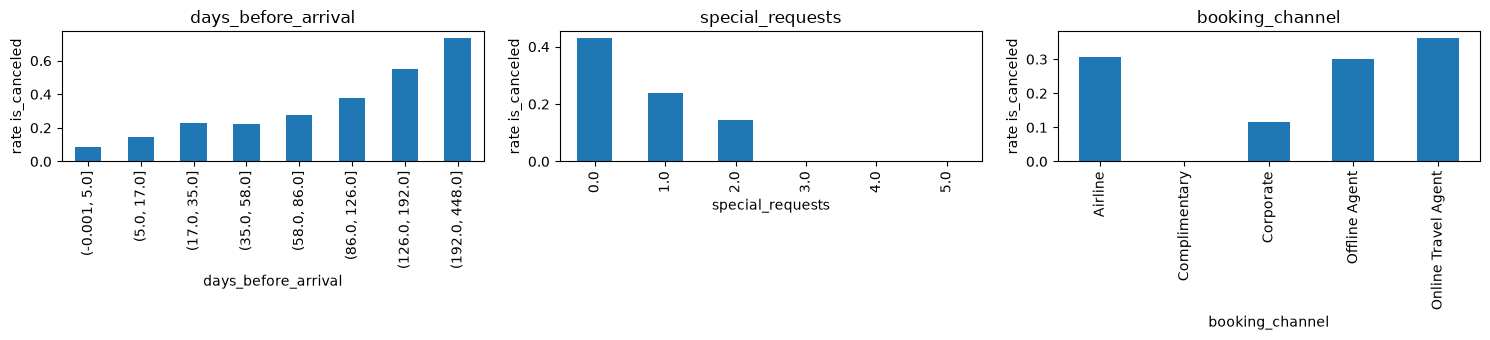

In [10]:
print(train_df[CFG.TARGET].value_counts(normalize=True).round(3))
target_rate(train_df, ['days_before_arrival', 'special_requests', 'booking_channel'], bins={'days_before_arrival': 8})

#### Insights

- Kelas tidak seimbang ringan, sekitar 33% batal. Macro F1 memberi bobot sama ke dua kelas, jadi threshold perlu ditentukan, bukan selalu 0.5.
- Lead time (`days_before_arrival`) dan `special_requests` paling kuat memisahkan kelas: booking jauh hari makin sering batal, tamu dengan permintaan khusus jarang batal. Dua fitur ini nanti diberi bobot 2 di jarak KNN.

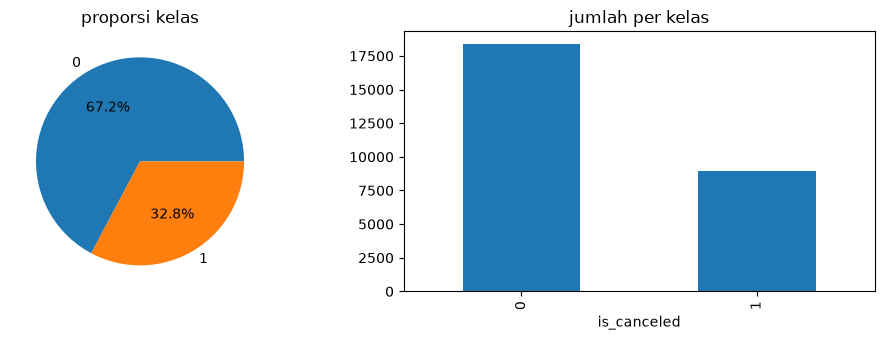

In [11]:
figure, axes = plt.subplots(1, 2, figsize=(10, 3.5))
train_df[CFG.TARGET].value_counts().plot.pie(ax=axes[0], autopct='%.1f%%', ylabel='', title='proporsi kelas')
train_df[CFG.TARGET].value_counts().plot.bar(ax=axes[1], title='jumlah per kelas')
plt.tight_layout()
plt.show()

Distribusi fitur numerik dipisah per kelas. `density=True` supaya dua kelas yang jumlahnya beda tetap bisa dibandingkan.

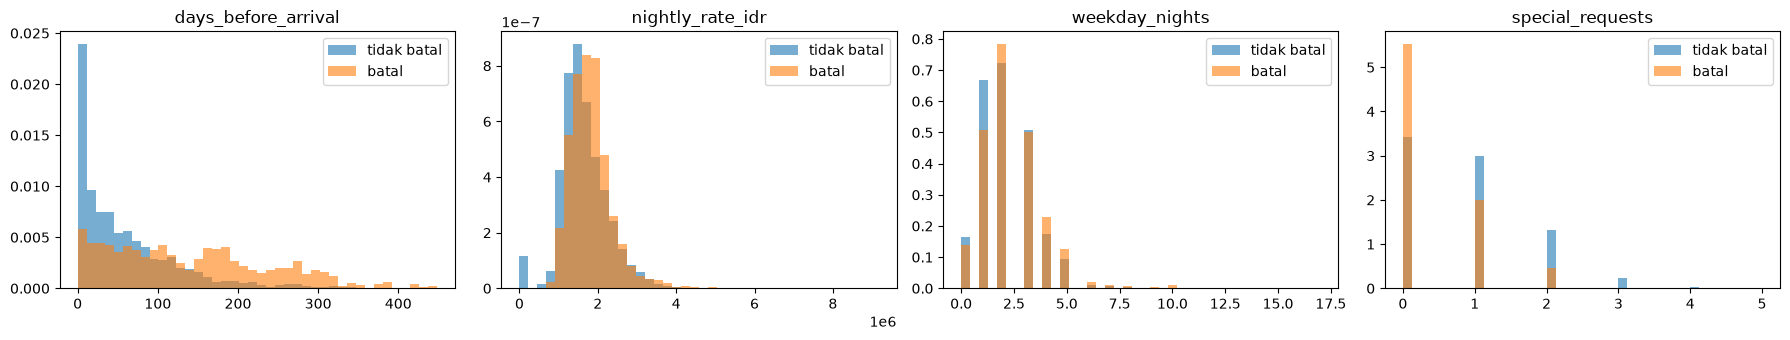

In [12]:
def histogram_by_target(df, columns, bins=40):
    figure, axes = plt.subplots(1, len(columns), figsize=(4.5 * len(columns), 3.5))
    for axis, column in zip(axes, columns):
        edges = np.histogram_bin_edges(df[column].dropna(), bins=bins)
        for label, name in [(0, 'tidak batal'), (1, 'batal')]:
            axis.hist(df.loc[df[CFG.TARGET] == label, column].dropna(), bins=edges, alpha=0.6, density=True, label=name)
        axis.set_title(column)
        axis.legend()
    plt.tight_layout()
    plt.show()

histogram_by_target(train_df, ['days_before_arrival', 'nightly_rate_idr', 'weekday_nights', 'special_requests'])

#### Insights

- Distribusi lead time kelas batal jauh lebih ke kanan. Rasio batal naik dari 8,8% (lead 0 sampai 5 hari) menjadi 73,8% (lead di atas 192 hari).
- Rasio batal naik seiring harga, dari 20,6% di kuintil termurah ke 44,5% di kuintil keempat, lalu turun sedikit di kuintil termahal (36,1%).
- Menginap lebih dari 10 malam punya rasio batal 68,7%, jauh di atas rata-rata.
- Tamu tanpa permintaan khusus batal 43,2%, dengan 1 permintaan 23,8%, dan dengan 3 atau lebih hampir tidak pernah batal.

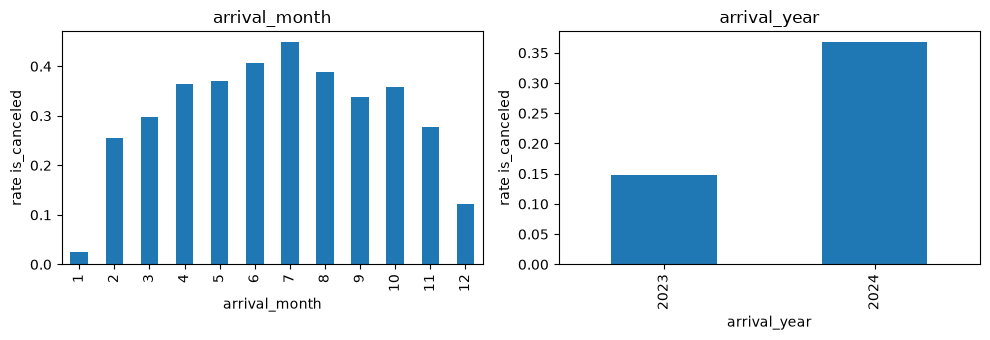

In [13]:
target_rate(train_df, ['arrival_month', 'arrival_year'])

#### Insights

- Ada pola musiman kuat: rasio batal terendah di Januari (2,6%) dan Desember (12,1%), tertinggi di Juli (44,8%).
- Korelasi linear `arrival_month` dengan target hampir 0 (-0,016) karena polanya naik lalu turun. Pola melingkar ini ditangkap oleh `month_cos`, yang membuat Desember dan Januari berdekatan.
- Tahun 2023 hanya 14,7% batal, sedangkan 2024 36,7%. `arrival_year` tidak dipakai langsung karena hanya 2 nilai dan sebagian besar efeknya sudah tertangkap lewat `booking_index`.

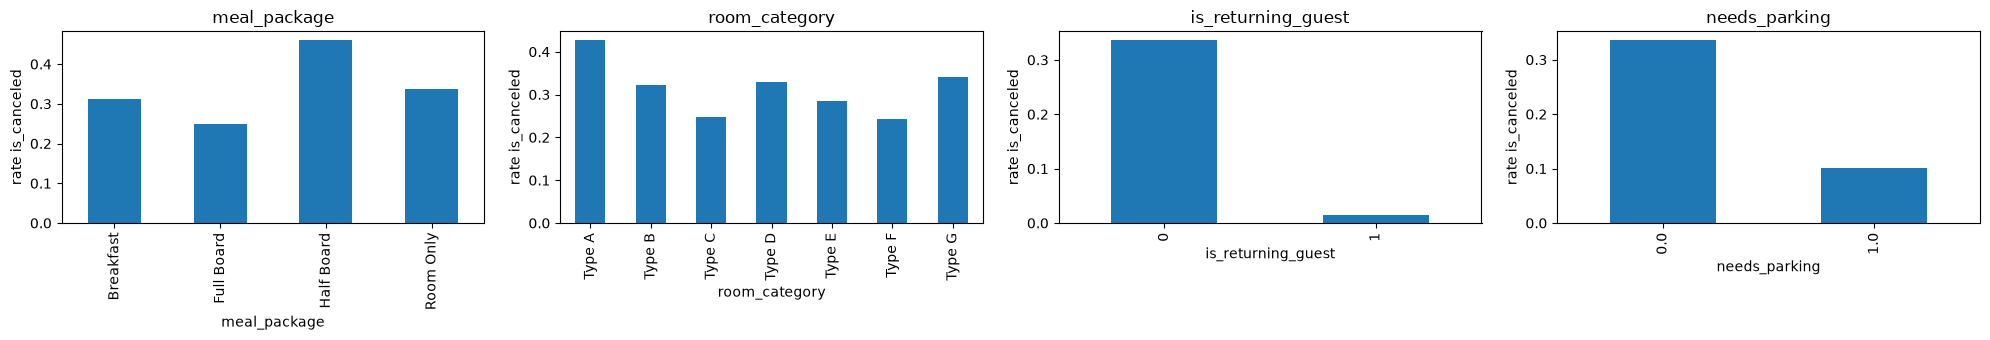

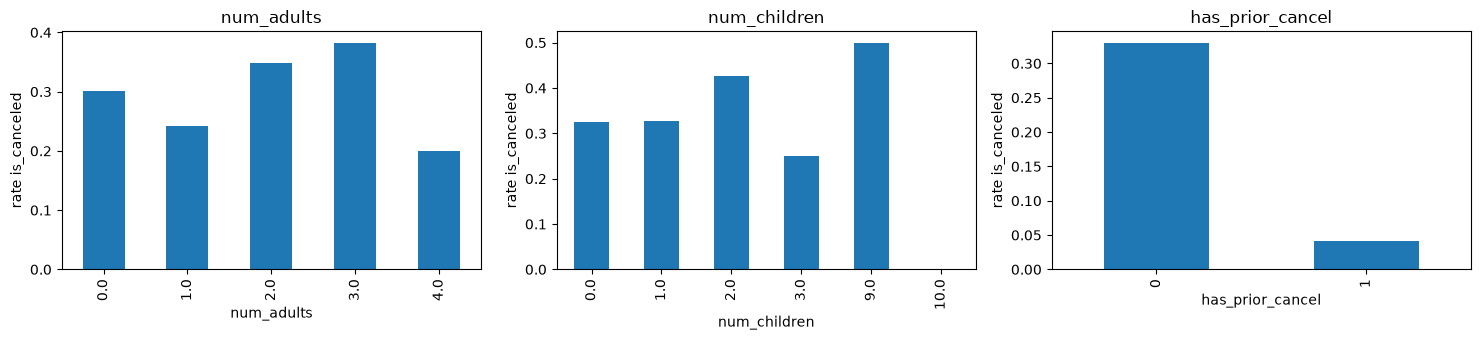

In [14]:
target_rate(train_df, ['meal_package', 'room_category', 'is_returning_guest', 'needs_parking'])
target_rate(train_df.assign(has_prior_cancel=(train_df['prior_cancellations'] > 0).astype(int)),
            ['num_adults', 'num_children', 'has_prior_cancel'])

#### Insights

- Kanal pemesanan sangat berpengaruh: Complimentary 0%, Corporate 11,5%, Offline Agent 30,2%, Online Travel Agent 36,4%.
- Tamu yang pernah menginap hampir tidak pernah batal (1,5% dibanding 33,6%). Tamu yang butuh parkir juga jarang batal (10,1% dibanding 33,5%).
- Paket Half Board paling sering batal (45,9%), sedangkan Full Board hanya 4 baris sehingga tidak bisa disimpulkan.
- Tamu dengan riwayat pembatalan justru jarang batal lagi, tetapi jumlahnya sangat sedikit (sekitar 1%).
- Beberapa kategori sangat jarang (Full Board 4 baris, Type E 7 baris, num_children 9 dan 10). Untuk KNN ini tidak masalah karena kategori jarang hanya menambah jarak.

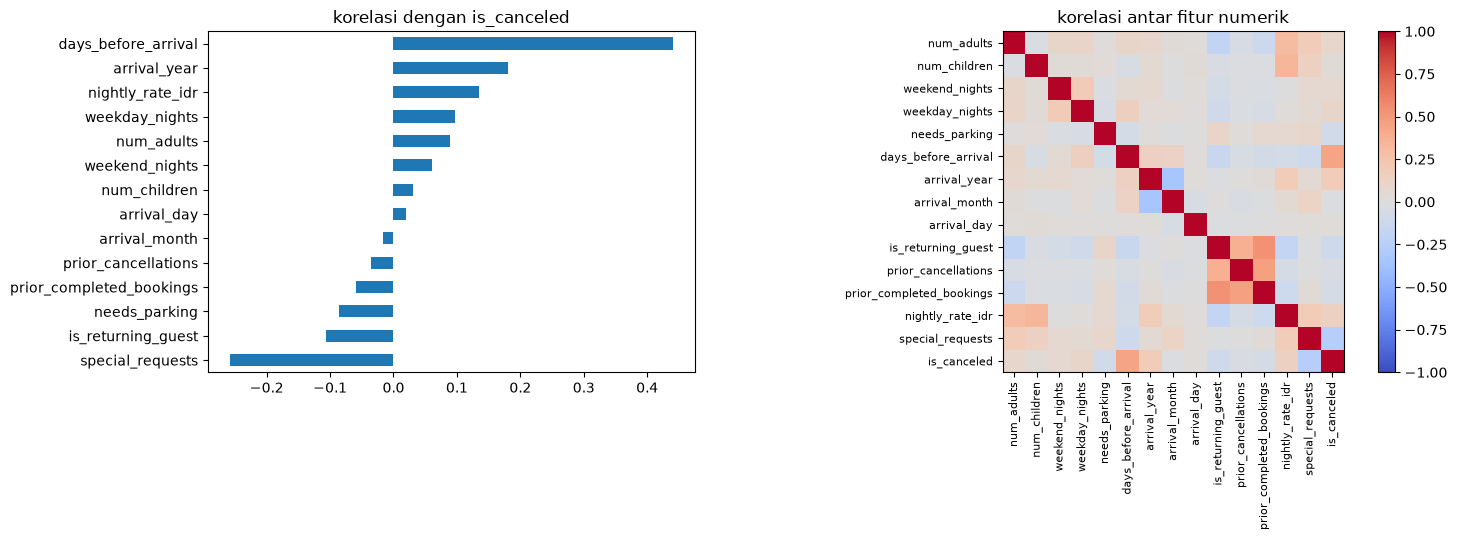

In [15]:
corr = train_df.select_dtypes('number').corr()
figure, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1, 1.4]})
corr[CFG.TARGET].drop(CFG.TARGET).sort_values().plot.barh(ax=axes[0], title='korelasi dengan is_canceled')
image = axes[1].imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
axes[1].set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
axes[1].set_yticks(range(len(corr)), corr.columns, fontsize=8)
axes[1].set_title('korelasi antar fitur numerik')
figure.colorbar(image, ax=axes[1])
plt.tight_layout()
plt.show()

#### Insights

- Korelasi terkuat dengan target: lead time (0,44), special_requests (-0,26), arrival_year (0,18), nightly_rate_idr (0,13), is_returning_guest (-0,11).
- Korelasi antarfitur rendah. Pasangan tertinggi hanya is_returning_guest dengan prior_completed_bookings (0,53), jadi tidak ada fitur yang benar-benar duplikat.
- Korelasi hanya menangkap hubungan linear. Bulan kedatangan berkorelasi hampir 0 tetapi polanya kuat (grafik musiman di atas), jadi seleksi fitur tidak boleh hanya berdasarkan korelasi.

### Booking kembar dan noise

Kami menemukan noise pada dataset ini. Untuk melihat kolom mana yang mengandung noise, kami mencari pasangan booking yang identik di semua kolom (kecuali lead time dan tanggal datang), lalu dibandingkan selisih lead time dan tanggal datangnya.

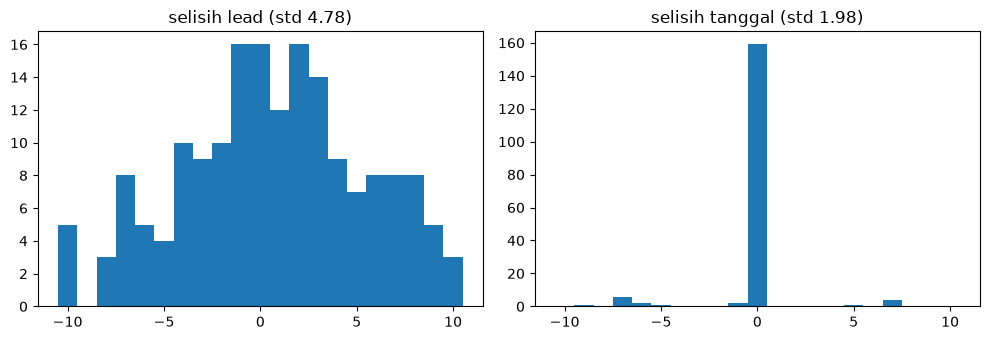

pasangan berdekatan: 176  label sama: 0.932  tanggal beda <= 1 hari: 0.915  lead beda <= 1 hari: 0.25


In [16]:
same_cols = ['weekend_nights', 'weekday_nights', 'booking_channel', 'is_returning_guest', 'prior_cancellations',
             'prior_completed_bookings', 'num_adults', 'num_children', 'needs_parking', 'meal_package', 'room_category',
             'special_requests', 'nightly_rate_idr']
pairs_df = train_df.dropna(subset=same_cols + ['days_before_arrival']).copy()
pairs_df['date'] = pd.to_datetime(dict(year=pairs_df['arrival_year'], month=pairs_df['arrival_month'], day=pairs_df['arrival_day']), errors='coerce')

rows = []
for _, group in pairs_df.groupby(same_cols):
    if 2 <= len(group) <= 20:
        first = group.iloc[0]
        for _, other in group.iloc[1:].iterrows():
            rows.append({'selisih lead': other['days_before_arrival'] - first['days_before_arrival'],
                         'selisih tanggal': (other['date'] - first['date']).days,
                         'label sama': other[CFG.TARGET] == first[CFG.TARGET]})
pairs = pd.DataFrame(rows)
near = pairs[(pairs['selisih lead'].abs() <= 10) & (pairs['selisih tanggal'].abs() <= 10)]

figure, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for axis, column in zip(axes, ['selisih lead', 'selisih tanggal']):
    axis.hist(near[column], bins=np.arange(-10.5, 11.5, 1))
    axis.set_title(f'{column} (std {near[column].std():.2f})')
plt.tight_layout()
plt.show()
print('pasangan berdekatan:', len(near), ' label sama:', round(near['label sama'].mean(), 3),
      ' tanggal beda <= 1 hari:', round((near['selisih tanggal'].abs() <= 1).mean(), 3),
      ' lead beda <= 1 hari:', round((near['selisih lead'].abs() <= 1).mean(), 3))

#### Insights

> Booking kembar hampir selalu punya label sama, dan noise ada di lead time.

- Ada 176 pasangan booking identik yang lead time dan tanggal datangnya berdekatan, dan 93% di antaranya punya label sama.
- Tanggal datang hampir selalu sama (91,5% beda paling banyak 1 hari, std 1,98), sedangkan lead time menyebar (hanya 25% beda paling banyak 1 hari, std 4,78). Jadi noise terutama ada di lead time.
- Temuan ini menjadi dasar fitur booking kembar di model: toleransi lead time dibuat longgar (10 hari), toleransi tanggal datang ketat (2 hari).

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [17]:
def missing(train, test):
    features = test.columns.drop(CFG.ID_COLUMN)
    table = pd.DataFrame({'train': train[features].isna().mean() * 100,
                          'test': test[features].isna().mean() * 100}).round(2)
    return table[table.sum(axis=1) > 0]

def duplicates(df):
    features = df.columns.drop([CFG.ID_COLUMN, CFG.TARGET])
    labels = df.groupby(list(features), dropna=False)[CFG.TARGET].nunique()
    return pd.Series({'baris duplikat': df.duplicated(subset=list(features) + [CFG.TARGET]).sum(),
                      'fitur sama, label beda': (labels > 1).sum()})

In [18]:
missing(train_df, test_df)

,train,test
num_adults,2.96,2.63
num_children,11.09,10.91
meal_package,6.43,6.46
needs_parking,3.95,3.61
room_category,3.66,3.54
days_before_arrival,4.10,4.24
nightly_rate_idr,7.45,7.89
special_requests,9.13,8.66


In [19]:
print(duplicates(train_df))
print('num_adults = 0:', (train_df['num_adults'] == 0).sum())

baris duplikat            64
fitur sama, label beda     2
dtype: int64
num_adults = 0: 106


#### Insights

- Missing ada di beberapa kolom (sekitar 2 sampai 11%) dengan proporsi mirip di train dan test, jadi imputasinya harus sama untuk keduanya.
- Ada baris duplikat persis. Kalau dibiarkan, baris yang sama bisa masuk data latih dan validasi sekaligus sehingga skor validasi terlalu optimis.
- Booking tanpa orang dewasa (`num_adults = 0`) tidak masuk akal, jadi dianggap nilai tidak valid.

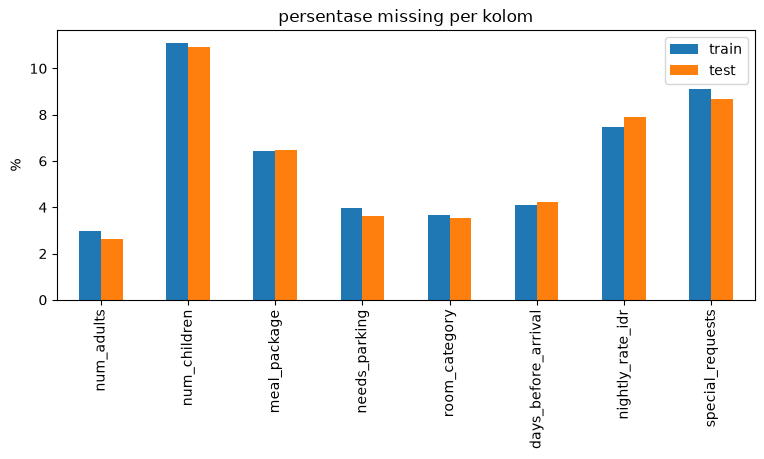

In [20]:
missing(train_df, test_df).plot.bar(figsize=(9, 3.5), title='persentase missing per kolom')
plt.ylabel('%')
plt.show()

Apakah baris yang missing punya rasio batal berbeda? Kalau berbeda, missing itu sendiri membawa informasi.

In [21]:
missing_cols = train_df.columns[train_df.isna().any()]
pd.DataFrame({'rasio batal jika missing': [train_df.loc[train_df[c].isna(), CFG.TARGET].mean() for c in missing_cols],
              'rasio batal jika terisi': [train_df.loc[train_df[c].notna(), CFG.TARGET].mean() for c in missing_cols]},
             index=missing_cols).round(3)

,rasio batal jika missing,rasio batal jika terisi
num_adults,0.335,0.327
num_children,0.328,0.328
meal_package,0.319,0.328
needs_parking,0.312,0.328
room_category,0.348,0.327
days_before_arrival,0.312,0.328
nightly_rate_idr,0.313,0.329
special_requests,0.408,0.320


Pengecekan nilai yang tidak masuk akal.

In [22]:
nights = train_df['weekend_nights'] + train_df['weekday_nights']
pd.Series({'num_adults = 0': (train_df['num_adults'] == 0).sum(),
           'total malam = 0': (nights == 0).sum(),
           'num_children >= 9': (train_df['num_children'] >= 9).sum(),
           'harga 0 bukan Complimentary': ((train_df['nightly_rate_idr'] == 0) & (train_df['booking_channel'] != 'Complimentary')).sum()},
          name='jumlah baris')

num_adults = 0                 106
total malam = 0                 64
num_children >= 9                3
harga 0 bukan Complimentary    146
Name: jumlah baris, dtype: int64

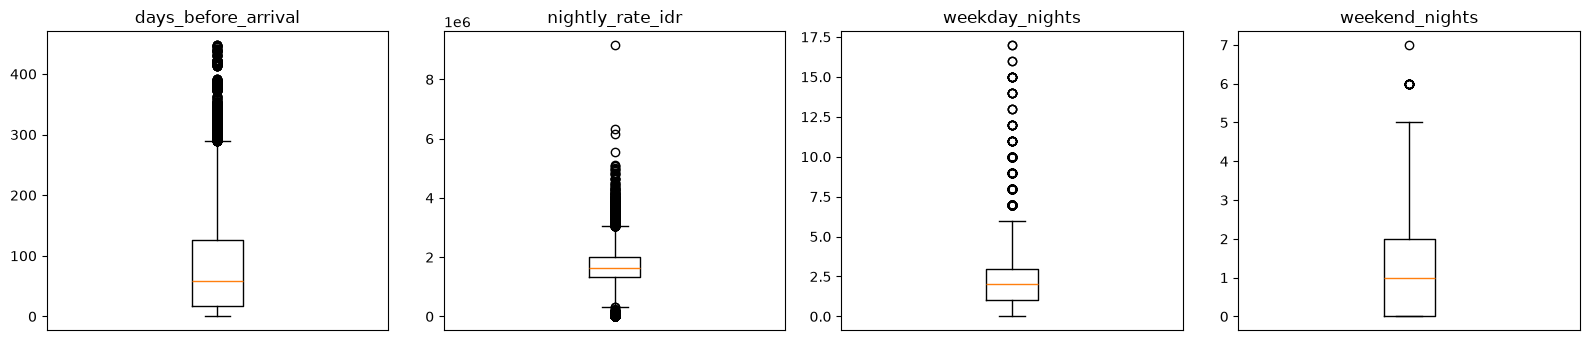

In [23]:
outlier_cols = ['days_before_arrival', 'nightly_rate_idr', 'weekday_nights', 'weekend_nights']
figure, axes = plt.subplots(1, len(outlier_cols), figsize=(4 * len(outlier_cols), 3.5))
for axis, column in zip(axes, outlier_cols):
    axis.boxplot(train_df[column].dropna())
    axis.set_title(column)
    axis.set_xticks([])
plt.tight_layout()
plt.show()

#### Insights

- Missing tersebar acak di 8 kolom: rasio batal baris missing dan terisi hampir sama (selisih di bawah 2 poin persen), kecuali `special_requests` (40,8% jika missing, 32,0% jika terisi). Indikator missing untuk special_requests sudah dicoba di eksperimen, tetapi tidak menaikkan OOF.
- Nilai tidak masuk akal: 106 baris tanpa orang dewasa, 64 baris dengan total malam 0, 3 baris dengan 9 atau 10 anak, dan 146 baris berharga 0 di luar kanal Complimentary. Hanya `num_adults = 0` yang diubah jadi missing, karena mengubah tiga kasus lainnya tidak menaikkan OOF.
- Boxplot menunjukkan ekor panjang di lead time (maksimum 448, persentil 99,5% = 382) dan harga (maksimum Rp9,17 juta, persentil 99,5% = Rp3,73 juta). Nilai ini ditangani dengan clipping di Data Preparation.

---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [24]:
# dedupe tidak mempelajari statistik apa pun, jadi dilakukan sebelum split supaya duplikat tidak bocor ke validasi
features = train_df.columns.drop([CFG.ID_COLUMN, CFG.TARGET])
train_clean = train_df.drop_duplicates(subset=list(features) + [CFG.TARGET]).reset_index(drop=True)
y_clean = train_clean[CFG.TARGET].to_numpy()

train_set, val_set = train_test_split(train_clean, test_size=CFG.TEST_SIZE, stratify=y_clean, random_state=CFG.SEED)
y_train, y_val = train_set[CFG.TARGET].to_numpy(), val_set[CFG.TARGET].to_numpy()

pd.Series({'train_clean': len(train_clean), 'train_set': len(train_set), 'val_set': len(val_set), 'test': len(test_df)})

train_clean    27309
train_set      21847
val_set         5462
test            6844
dtype: int64

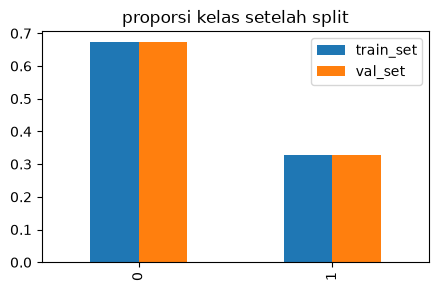

In [25]:
pd.DataFrame({'train_set': pd.Series(y_train).value_counts(normalize=True),
              'val_set': pd.Series(y_val).value_counts(normalize=True)}).plot.bar(figsize=(5, 3), title='proporsi kelas setelah split')
plt.show()

#### Insights

> Holdout 20% stratified, setelah dedupe.

- Dedupe dilakukan sebelum split. Langkah ini tidak mempelajari statistik apa pun, dan mencegah baris yang sama muncul di data latih dan validasi sekaligus.
- Split 80:20 memakai `stratify` sehingga proporsi kelas batal sama (32,8%) di train_set dan val_set.
- Semua statistik preprocessing (batas clip, median, modus, IQR, level kategori) dihitung dari train_set saja, lalu diterapkan ke val_set dan test.
- Selain holdout, model juga dinilai dengan 5-fold cross validation di bagian Improvements supaya skor tidak bergantung pada satu pembagian.

---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [26]:
num_col  = ['num_adults', 'weekend_nights', 'weekday_nights', 'needs_parking', 'days_before_arrival', 'arrival_day',
            'is_returning_guest', 'prior_cancellations', 'nightly_rate_idr', 'special_requests',
            'booking_index', 'month_cos']
cat_col  = ['meal_package', 'room_category', 'booking_channel']
clip_col = ['num_adults', 'weekend_nights', 'weekday_nights', 'days_before_arrival', 'nightly_rate_idr',
            'prior_cancellations', 'special_requests']

print('fitur dipakai:', len(num_col) + len(cat_col))
print('kolom tidak dipakai:', [c for c in features if c not in num_col + cat_col])

fitur dipakai: 15
kolom tidak dipakai: ['num_children', 'arrival_year', 'arrival_month', 'prior_completed_bookings']


Fungsi preparation di bawah bekerja pada list `frames`. Statistik selalu diambil dari `frames[0]` (data fit), lalu diterapkan ke semua frame. Di tiap bagian, fungsi dicoba pada salinan `train_set` dan `val_set`. Urutan lengkapnya digabung di bagian Preparation Pipeline.

In [27]:
demo = [train_set.copy(), val_set.copy()]

#### Insights

- Fitur dipilih lewat forward selection dan pengecekan OOF di beberapa seed.
- Kolom tahun dan bulan mentah diganti `month_cos` (musim) dan `booking_index` (tanggal booking). Kolom yang tidak menaikkan OOF dibuang supaya jarak KNN tidak dikotori fitur yang tidak informatif.

## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

`impute` mengisi missing dengan median (numerik) atau modus (kategorikal) dari data fit.

- `columns` berisi kolom yang diisi
- `strategy` bernilai `'median'` atau `'most_frequent'`

In [28]:
def impute(frames, columns, strategy='median'):
    fit = frames[0][columns]
    values = fit.median() if strategy == 'median' else fit.mode().iloc[0]
    for frame in frames:
        frame[columns] = frame[columns].fillna(values)

In [29]:
raw = [c for c in num_col if c in features]
print('missing sebelum:', int(demo[0][raw + cat_col].isna().sum().sum()))
impute(demo, raw, 'median')
impute(demo, cat_col, 'most_frequent')
print('missing sesudah:', int(demo[0][raw + cat_col].isna().sum().sum()))

missing sebelum: 8186
missing sesudah: 0


#### Insights

> Numerik diisi median, kategorikal diisi modus, keduanya dari data fit.
- Median dipilih setelah dibandingkan dengan mean, modus, KNN imputation, group median, imputasi sebelum feature engineering, dan jarak yang mengabaikan kolom missing. Semua alternatif lebih rendah di OOF.
- Di pipeline, imputasi dilakukan setelah fitur turunan dibuat, supaya `booking_index` dari lead time yang kosong ikut terisi.

### Duplicates

This part covers repeated records.

In [30]:
print('sebelum', len(train_df), ' sesudah dedupe', len(train_clean), ' dibuang', len(train_df) - len(train_clean))

sebelum 27373  sesudah dedupe 27309  dibuang 64


#### Insights

> Baris duplikat (fitur dan label sama) dibuang, yang pertama disimpan.
- Dedupe dilakukan di bagian Training and Validation Split, sebelum data dibagi.

### Outliers

This part covers values far from the rest of the data.

`cap_outliers` memotong nilai di luar persentil `q` dan `1 - q` data fit. Kolom yang batas bawah dan atasnya sama tidak dipotong.

In [31]:
def cap_outliers(frames, columns, q=0.005):
    lower, upper = frames[0][columns].quantile(q), frames[0][columns].quantile(1 - q)
    same = lower >= upper
    lower, upper = lower.where(~same, -np.inf), upper.where(~same, np.inf)
    for frame in frames:
        frame[columns] = frame[columns].clip(lower, upper, axis=1)

In [32]:
before = demo[0][clip_col].copy()
cap_outliers(demo, clip_col, CFG.CLIP_QUANTILE)
(before != demo[0][clip_col]).sum().rename('baris terpotong')

num_adults             106
weekend_nights          34
weekday_nights          95
days_before_arrival    110
nightly_rate_idr       110
prior_cancellations     80
special_requests        56
Name: baris terpotong, dtype: int64

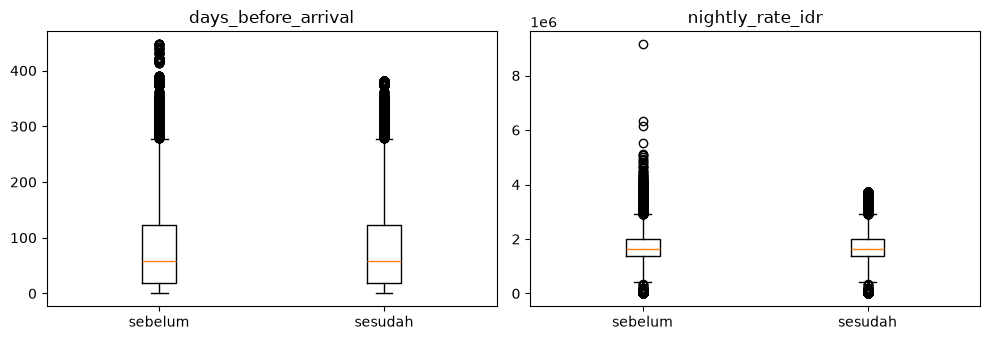

In [33]:
figure, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for axis, column in zip(axes, ['days_before_arrival', 'nightly_rate_idr']):
    axis.boxplot([before[column].dropna(), demo[0][column].dropna()])
    axis.set_xticks([1, 2], ['sebelum', 'sesudah'])
    axis.set_title(column)
plt.tight_layout()
plt.show()

#### Insights

> Outlier dipotong ke persentil 0.5% dan 99.5% data fit (winsorizing).
- Robust scaler tidak terpengaruh outlier saat menghitung median dan IQR, tetapi nilai ekstrem tetap bisa mendominasi jarak Minkowski.
- Persentil 0.5% dan 99.5% lebih baik daripada persentil 1% dan IQR 3x di OOF.
- Lead time dan harga masing-masing dipotong di 110 baris train_set. Boxplot sesudah clipping tidak lagi punya titik ekstrem jauh di atas, sehingga sebaran utama tetap sama.
- Di demo ini `num_adults` ikut terpotong karena nilai 0 naik ke batas bawah 1. Di pipeline, `mark_invalid` dijalankan lebih dulu sehingga nilai 0 sudah menjadi missing sebelum clipping.

### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [34]:
def mark_invalid(frames):
    for frame in frames:
        frame.loc[frame['num_adults'] == 0, 'num_adults'] = np.nan

In [35]:
print('num_adults = 0 di train_set:', (train_set['num_adults'] == 0).sum())

num_adults = 0 di train_set: 92


#### Insights

> `num_adults = 0` dianggap data error, diubah jadi missing lalu diisi median.
- Alternatif yang dicoba (dibiarkan 0, ditukar dengan num_children, flag terpisah, buang baris) tidak lebih baik.

## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

<!-- rubric v3: derived columns, rate_per_guest_night -->

This part covers new attributes derived from existing ones.

In [36]:
def engineer(frames):
    for frame in frames:
        arrival = pd.to_datetime(dict(year=frame['arrival_year'], month=frame['arrival_month'], day=frame['arrival_day']),
                                 errors='coerce')
        frame['booking_index'] = (arrival - pd.Timestamp('2023-01-01')).dt.days.astype(float) - frame['days_before_arrival']
        frame['month_cos'] = np.cos(2 * np.pi * frame['arrival_month'] / 12)

In [37]:
engineer(demo)
demo[0][['arrival_year', 'arrival_month', 'arrival_day', 'days_before_arrival', 'booking_index', 'month_cos']].head()

,arrival_year,arrival_month,arrival_day,days_before_arrival,booking_index,month_cos
23158,2024,11,23,45.0,647.0,8.660254e-01
6939,2024,6,22,6.0,532.0,-1.000000e+00
22591,2024,2,22,11.0,406.0,5.000000e-01
16914,2024,3,18,120.0,322.0,6.123234e-17
16072,2024,9,2,254.0,356.0,-1.836970e-16


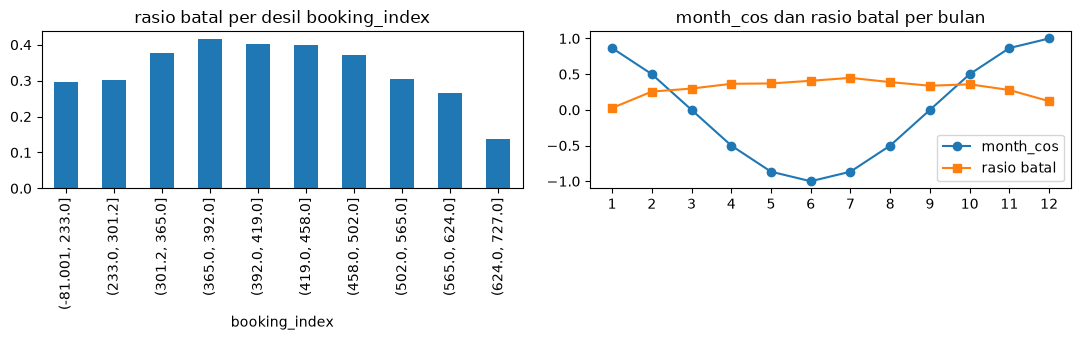

In [38]:
figure, axes = plt.subplots(1, 2, figsize=(11, 3.5))
demo[0].groupby(pd.qcut(demo[0]['booking_index'], 10, duplicates='drop'), observed=True)[CFG.TARGET].mean().plot.bar(ax=axes[0])
axes[0].set_title('rasio batal per desil booking_index')
month = np.arange(1, 13)
axes[1].plot(month, np.cos(2 * np.pi * month / 12), marker='o', label='month_cos')
axes[1].plot(month, train_df.groupby('arrival_month')[CFG.TARGET].mean().to_numpy(), marker='s', label='rasio batal')
axes[1].set_xticks(month)
axes[1].set_title('month_cos dan rasio batal per bulan')
axes[1].legend()
plt.tight_layout()
plt.show()

#### Insights

- `booking_index` = hari kedatangan (sejak 2023-01-01) dikurangi lead time, yaitu kapan booking dibuat.
- `month_cos` = cos(2 pi bulan / 12), supaya Desember dan Januari berdekatan.
- Rasio batal per desil `booking_index` sekitar 29 sampai 32% di dua desil awal, naik ke puncak 42%, lalu turun tajam ke 13% di desil terakhir. Booking yang dibuat paling akhir (dekat akhir periode data) jarang tercatat batal.
- Garis `month_cos` bernilai tinggi di Desember dan Januari, tepat saat rasio batal paling rendah, dan rendah di pertengahan tahun saat rasio batal tinggi. Satu kolom ini cukup menangkap pola musiman.

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

`scale` melakukan robust scaling (x - median) / IQR dengan statistik dari data fit. Kalau IQR 0, dipakai simpangan baku. `weight` lalu mengalikan kolom dengan bobot fitur.

In [39]:
def scale(frames, columns):
    fit = frames[0][columns].astype(float)
    center = fit.median()
    spread = fit.quantile(0.75) - fit.quantile(0.25)
    spread = spread.where(spread > 0, fit.std()).replace(0, 1)
    for frame in frames:
        frame[columns] = (frame[columns].astype(float) - center) / spread

def weight(frames, weights):
    for frame in frames:
        for column, value in weights.items():
            frame[column] = frame[column] * value

In [40]:
impute(demo, ['booking_index'], 'median')
scale(demo, num_col)
weight(demo, CFG.FEATURE_WEIGHTS)
demo[0][num_col].describe().T[['mean', 'std', '50%']].round(3)

,mean,std,50%
num_adults,-0.075,0.250,0.0
weekend_nights,-0.092,0.433,0.0
weekday_nights,0.048,0.337,0.0
needs_parking,0.087,0.500,0.0
days_before_arrival,0.503,1.612,0.0
arrival_day,-0.027,0.586,0.0
is_returning_guest,0.161,1.000,0.0
prior_cancellations,0.094,1.000,0.0
nightly_rate_idr,0.104,0.897,0.0
special_requests,1.205,1.549,0.0


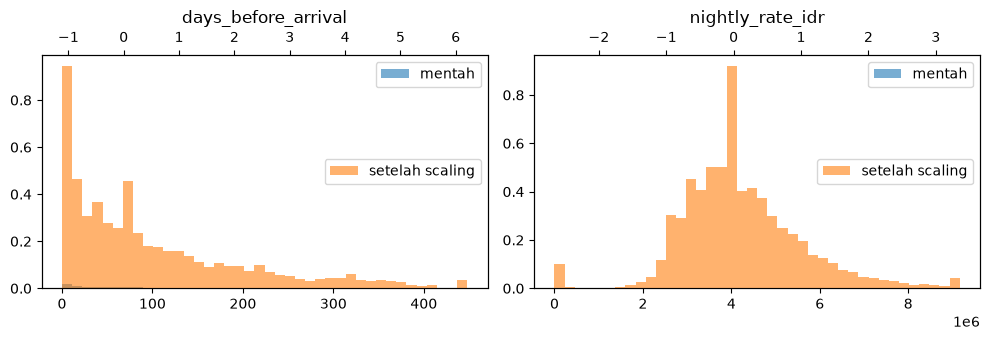

        days_before_arrival  nightly_rate_idr  special_requests
median                 0.00              0.00               0.0
min                   -1.12             -2.66               0.0
max                    6.21              3.35               6.0


In [41]:
figure, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for axis, column in zip(axes, ['days_before_arrival', 'nightly_rate_idr']):
    axis.hist(train_set[column].dropna(), bins=40, alpha=0.6, density=True, label='mentah')
    twin_axis = axis.twiny()
    twin_axis.hist(demo[0][column], bins=40, alpha=0.6, density=True, color='tab:orange', label='setelah scaling')
    axis.set_title(column)
    axis.legend(loc='upper right'); twin_axis.legend(loc='center right')
plt.tight_layout()
plt.show()
print(demo[0][['days_before_arrival', 'nightly_rate_idr', 'special_requests']].agg(['median', 'min', 'max']).round(2))

#### Insights

> Kolom numerik di-scale dengan robust scaler lalu diberi bobot fitur.
- Robust scaler paling tinggi di OOF dibanding z-score, min-max, dan rank karena tidak terpengaruh outlier.
- Bobot fitur didapat dari coordinate search: lead time dan special_requests x2, num_adults x0.25.
- Setelah robust scaling, median tiap kolom menjadi 0 dan lebar IQR menjadi 1, sehingga lead time (puluhan hari) dan harga (jutaan rupiah) punya skala yang sebanding. Bentuk distribusinya tidak berubah.
- Setelah diberi bobot, lead time berada di rentang -1,12 sampai 6,21. Bobot 2 membuat selisih lead time terhitung dua kali lipat di jarak KNN.

### Encoding

This part covers the numeric representation of categorical attributes.

`encode` membuat kolom onehot dari level kategori di data fit. Nilai onehot `value` bisa lebih kecil dari 1.

In [42]:
def encode(frames, columns, value=1.0):
    names = []
    for column in columns:
        for level in sorted(frames[0][column].dropna().unique()):
            for frame in frames:
                frame[f'{column}_{level}'] = (frame[column] == level) * value
            names.append(f'{column}_{level}')
    return names

In [43]:
onehot_col = encode(demo, cat_col, CFG.ONEHOT_VALUE)
onehot_col

['meal_package_Breakfast',
 'meal_package_Full Board',
 'meal_package_Half Board',
 'meal_package_Room Only',
 'room_category_Type A',
 'room_category_Type B',
 'room_category_Type C',
 'room_category_Type D',
 'room_category_Type E',
 'room_category_Type F',
 'room_category_Type G',
 'booking_channel_Airline',
 'booking_channel_Complimentary',
 'booking_channel_Corporate',
 'booking_channel_Offline Agent',
 'booking_channel_Online Travel Agent']

#### Insights

> Kategori di-onehot karena tidak punya urutan bermakna.
- Nilai onehot 0.75, bukan 1, supaya beda kategori tidak terlalu besar dibanding beda fitur numerik yang sudah di-scale.

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

In [44]:
print(len(features), 'kolom mentah ->', len(num_col) + len(cat_col), 'fitur ->', len(num_col) + len(onehot_col), 'kolom setelah onehot')

17 kolom mentah -> 15 fitur -> 28 kolom setelah onehot


#### Insights

> Reduksi dimensi dilakukan dengan seleksi fitur.
- Seleksi fitur dipilih daripada PCA supaya fitur tetap bisa dijelaskan dan diberi bobot sendiri-sendiri.

## Class Balance

This part covers the proportion of each class in the training data.

In [45]:
pd.Series(y_train).value_counts(normalize=True).round(3)

0    0.672
1    0.328
Name: proportion, dtype: float64

#### Insights

> Tidak dilakukan oversampling atau undersampling.
- Ketidakseimbangan ringan (sekitar 67:33) dan Macro F1 sudah memberi bobot sama ke dua kelas.
- Ketidakseimbangan ditangani dengan threshold probabilitas yang memaksimalkan Macro F1.

## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [46]:
X_demo = demo[1][num_col + onehot_col].to_numpy(np.float32)
print(X_demo.dtype, X_demo.shape)
X_demo[:3].round(3)

float32 (5462, 28)


array([[-0.503, -0.5  ,  0.   ,  0.   , -0.846,  0.533,  0.   ,  0.   ,
        -0.868,  2.   , -0.073,  0.5  ,  0.75 ,  0.   ,  0.   ,  0.   ,
         0.   ,  0.75 ,  0.   ,  0.   ,  0.   ,  0.   ,  0.   ,  0.   ,
         0.   ,  0.   ,  0.   ,  0.75 ],
       [-0.503,  0.   ,  0.   ,  0.   , -0.75 , -0.533,  0.   ,  0.   ,
         0.181,  4.   ,  0.922,  0.   ,  0.75 ,  0.   ,  0.   ,  0.   ,
         0.   ,  0.   ,  0.   ,  0.75 ,  0.   ,  0.   ,  0.   ,  0.   ,
         0.   ,  0.   ,  0.   ,  0.75 ],
       [-0.503,  0.5  ,  0.   ,  0.   ,  2.981, -0.733,  0.   ,  0.   ,
         1.411,  2.   ,  0.218,  0.866,  0.75 ,  0.   ,  0.   ,  0.   ,
         0.   ,  0.75 ,  0.   ,  0.   ,  0.   ,  0.   ,  0.   ,  0.   ,
         0.   ,  0.   ,  0.   ,  0.75 ]], dtype=float32)

---

# Preparation Pipeline <a name="6"></a>

---

<!-- rubric v3: fitted steps, fitted_prep_steps -->

The pipeline combines the preparation steps so they run in one consistent order.

In [47]:
# preprocessing bersama untuk SEMUA model, dengan urutan:
# data error jadi missing, clipping, fitur turunan, imputasi, robust scaling, bobot fitur, onehot.
# Statistik diambil dari fit_df saja. Hasilnya matriks float32 untuk fit_df dan tiap df lain.
def prepare(fit_df, *dfs):
    frames = [df.copy() for df in (fit_df,) + dfs]
    mark_invalid(frames)
    cap_outliers(frames, clip_col, CFG.CLIP_QUANTILE)
    engineer(frames)
    impute(frames, num_col, 'median')
    impute(frames, cat_col, 'most_frequent')
    scale(frames, num_col)
    weight(frames, CFG.FEATURE_WEIGHTS)
    columns = num_col + encode(frames, cat_col, CFG.ONEHOT_VALUE)
    return [frame[columns].to_numpy(np.float32) for frame in frames]

In [48]:
X_train, X_val, X_test = prepare(train_set, val_set, test_df)
pd.Series({'X_train': X_train.shape, 'X_val': X_val.shape, 'X_test': X_test.shape})

X_train    (21847, 28)
X_val       (5462, 28)
X_test      (6844, 28)
dtype: object

Model lain (DTL, Logistic Regression, SVM, Naive Bayes) memakai `X_train`, `X_val`, dan `X_test` yang sama. Untuk k-fold atau training final, panggil ulang `prepare(fit_df, ...)` dengan data fit yang baru.

---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

## K-Nearest Neighbors

<!-- rubric v3: pairwise distances, val_neighbor_dists -->

This part covers the nearest neighbor classifier and its validation.

`KNN` from scratch dengan jarak Minkowski dan bobot vote 1/d². Jarak dijumlah per kolom dalam float32, lalu diambil k tetangga terdekat.

- `k` berisi jumlah tetangga
- `p` berisi orde jarak Minkowski

In [49]:
class KNN:
    def __init__(self, k=5, p=2.0, batch=1024):
        self.k, self.p, self.batch = k, p, batch

    def fit(self, X, y):
        self.X, self.y = X, np.asarray(y).astype(int)
        return self

    def kneighbors(self, Q):
        dists, ids = [], []
        for start in range(0, len(Q), self.batch):
            q = Q[start:start + self.batch]
            D = np.zeros((len(q), len(self.X)), np.float32)
            for j in range(self.X.shape[1]):
                D += np.abs(q[:, j, None] - self.X[None, :, j]) ** self.p
            idx = np.argpartition(D, self.k - 1, axis=1)[:, :self.k]
            d = np.take_along_axis(D, idx, 1)
            order = np.argsort(d, axis=1, kind='stable')
            ids.append(np.take_along_axis(idx, order, 1))
            dists.append(np.take_along_axis(d, order, 1) ** (1 / self.p))
        return np.vstack(dists), np.vstack(ids)

    def predict_proba(self, Q):
        d, idx = self.kneighbors(Q)
        w = 1 / (d ** 2 + 1e-6)
        return (w * self.y[idx]).sum(1) / w.sum(1)

    def predict(self, Q, threshold=0.5):
        return (self.predict_proba(Q) >= threshold).astype(int)

`twin_vote` mencari booking kembar di data latih untuk tiap baris: kolom `twin_key` sama persis, kolom `twin_soft` sama (missing dianggap cocok), selisih lead time, tanggal datang, dan harga di bawah toleransi. Hasilnya proporsi kembar yang batal dan jumlah kembar.

In [50]:
twin_key  = ['weekend_nights', 'weekday_nights', 'booking_channel', 'is_returning_guest', 'prior_cancellations',
             'prior_completed_bookings']
twin_soft = ['num_adults', 'num_children', 'needs_parking', 'meal_package', 'room_category', 'special_requests']

def arrival_date(df):
    return pd.to_datetime(dict(year=df['arrival_year'], month=df['arrival_month'], day=df['arrival_day']), errors='coerce')

def twin_vote(A, B, y_B, lead, day, price):
    A, B = A.reset_index(drop=True), B.reset_index(drop=True)
    A, B = A.assign(date=arrival_date(A)), B.assign(date=arrival_date(B))
    share, count = np.full(len(A), np.nan), np.zeros(len(A), int)
    groups_b = B.groupby(twin_key, dropna=False).indices
    for key, ia in A.groupby(twin_key, dropna=False).indices.items():
        ib = groups_b.get(key)
        if ib is None:
            continue
        a, b = A.iloc[ia], B.iloc[ib]
        ok = np.ones((len(ia), len(ib)), bool)
        for c in twin_soft:
            x, z = a[c].to_numpy()[:, None], b[c].to_numpy()[None, :]
            ok &= (x == z) | pd.isna(x) | pd.isna(z)
        x, z = a['days_before_arrival'].to_numpy(float)[:, None], b['days_before_arrival'].to_numpy(float)[None, :]
        ok &= (np.abs(x - z) <= lead) | np.isnan(x) | np.isnan(z)
        dd = np.abs((a['date'].to_numpy()[:, None] - b['date'].to_numpy()[None, :]) / np.timedelta64(1, 'D')).astype(float)
        ok &= (dd <= day) | np.isnan(dd)
        x, z = a['nightly_rate_idr'].to_numpy(float)[:, None], b['nightly_rate_idr'].to_numpy(float)[None, :]
        ok &= (np.abs(x - z) <= price * np.maximum(z, 1)) | np.isnan(x) | np.isnan(z)
        n = ok.sum(1)
        share[ia] = np.where(n > 0, (ok * y_B[ib][None, :]).sum(1) / np.maximum(n, 1), np.nan)
        count[ia] = n
    return share, count

`KNNTwin` adalah model akhir. KNN itu lazy learner, jadi `fit` cukup menyimpan data latih. Saat prediksi, preprocessing di-fit pada data latih, lalu kalau ada minimal `TWIN_MIN` kembar, probabilitas = (1 - alpha) x vote KNN + alpha x proporsi kembar yang batal.

In [51]:
class KNNTwin:
    def __init__(self, k, p, threshold):
        self.k, self.p, self.threshold = k, p, threshold

    def fit(self, df):
        self.train_df = df.reset_index(drop=True)
        self.y = self.train_df[CFG.TARGET].to_numpy().astype(int)
        return self

    def predict_knn(self, df):
        X_fit, X_df = prepare(self.train_df, df)
        return KNN(self.k, self.p).fit(X_fit, self.y).predict_proba(X_df)

    def predict_proba(self, df):
        proba = self.predict_knn(df)
        share, count = twin_vote(df, self.train_df, self.y, CFG.TWIN_LEAD, CFG.TWIN_DAY, CFG.TWIN_PRICE)
        use = count >= CFG.TWIN_MIN
        proba[use] = (1 - CFG.TWIN_ALPHA) * proba[use] + CFG.TWIN_ALPHA * share[use]
        return proba

    def predict(self, df):
        return (self.predict_proba(df) >= self.threshold).astype(int)

In [52]:
def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average='macro')

def best_threshold(y_true, proba):
    grid = np.round(np.arange(0.20, 0.81, 0.01), 2)
    return float(grid[np.argmax([macro_f1(y_true, proba >= t) for t in grid])])

knn = KNNTwin(CFG.K, CFG.P, CFG.THRESHOLD).fit(train_set)
val_knn = knn.predict_knn(val_set)
val_twin = knn.predict_proba(val_set)

RESULTS = {'KNN + kembar': macro_f1(y_val, val_twin >= CFG.THRESHOLD),
           'KNN saja': macro_f1(y_val, val_knn >= best_threshold(y_val, val_knn))}
pd.Series(RESULTS, name='holdout').round(4)

KNN + kembar    0.8592
KNN saja        0.8539
Name: holdout, dtype: float64

#### Insights

- Kami menemukan noise pada data ini, terutama di lead time. Booking yang hampir identik (kembar) hampir selalu punya label sama, jadi vote kembar lebih bisa dipercaya daripada vote k tetangga biasa.
- Toleransi lead dibuat longgar (10 hari) dan tanggal datang ketat (2 hari) karena noise ada di lead time.

## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

DTL memakai model dan langkah dari eksperimen `src/experiments/dtl/dtl_gain_ratio.ipynb` (public 0.84679), yaitu DTL terbaik.

**Preprocessing khusus DTL.** Dedupe dan `mark_invalid` sama dengan KNN. Bedanya, DTL tidak memakai clipping, imputasi, scaling, maupun onehot, karena `DecisionTree` from scratch bisa membaca missing dan kategori langsung. Yang ditambahkan hanya 7 fitur turunan dan penggabungan kategori langka (kurang dari 20 baris di data fit menjadi `Other`).

`DecisionTree` from scratch memenuhi syarat spesifikasi:

- **Numerik**: split berbentuk `kolom <= threshold`, semua titik tengah antar nilai unik dicoba.
- **Categorical**: kolom bertipe teks dikenali otomatis, kategorinya dibagi jadi dua kelompok terbaik.
- **Null values**: saat training, baris yang missing di sebuah split diarahkan ke cabang yang membuat impurity paling kecil, dan arah itu disimpan untuk prediksi.
- **Algoritma**: C4.5, yaitu criterion gain ratio (information gain dibagi split information) dengan split biner.

In [53]:
new_col = ['total_nights', 'total_guests', 'is_free', 'rate_per_guest', 'arrival_weekday', 'arrival_dayofyear', 'arrival_index']

# 7 fitur turunan dari eksperimen DT
def add_features(frames):
    for frame in frames:
        frame['total_nights'] = frame['weekend_nights'] + frame['weekday_nights']
        frame['total_guests'] = frame['num_adults'] + frame['num_children']
        frame['is_free'] = (frame['nightly_rate_idr'] == 0).astype(float)
        frame.loc[frame['nightly_rate_idr'].isna(), 'is_free'] = np.nan
        frame['rate_per_guest'] = frame['nightly_rate_idr'] / frame['total_guests'].replace(0, np.nan)
        arrival = pd.to_datetime(dict(year=frame['arrival_year'], month=frame['arrival_month'], day=frame['arrival_day']),
                                 errors='coerce')
        frame['arrival_weekday'] = arrival.dt.day_of_week.astype(float)
        frame['arrival_dayofyear'] = arrival.dt.day_of_year.astype(float)
        frame['arrival_index'] = (arrival - pd.Timestamp('2023-01-01')).dt.days.astype(float)

# kategori yang muncul kurang dari min_count kali di data fit digabung jadi 'Other'
def group_rare(frames, columns, min_count=20):
    for column in columns:
        counts = frames[0][column].value_counts()
        keep = sorted(counts[counts >= min_count].index)
        for frame in frames:
            known = frame[column].isin(keep) | frame[column].isna()
            frame.loc[~known, column] = 'Other'

# preprocessing DTL: data error jadi missing, fitur turunan, buang id dan target, gabung kategori langka.
# Missing dan kategori dibiarkan karena ditangani langsung oleh pohon.
def prepare_tree(fit_df, *dfs):
    frames = [df.copy() for df in (fit_df,) + dfs]
    mark_invalid(frames)
    add_features(frames)
    frames = [frame.drop(columns=[c for c in [CFG.ID_COLUMN, CFG.TARGET] if c in frame.columns]) for frame in frames]
    group_rare(frames, cat_col, CFG.RARE_MIN_COUNT)
    return frames

X_train_dt, X_val_dt = prepare_tree(train_set, val_set)
print(X_train_dt.shape, ' NaN tersisa', int(X_train_dt.isna().sum().sum()))
X_train_dt.head(3)

(21847, 24)  NaN tersisa 19933


,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,...,prior_completed_bookings,nightly_rate_idr,special_requests,total_nights,total_guests,is_free,rate_per_guest,arrival_weekday,arrival_dayofyear,arrival_index
23158,2.0,0.0,2,3,Breakfast,0.0,Type G,45.0,2024,11,...,0,1634000.0,2.0,5,2.0,0.0,817000.0,5.0,328.0,692.0
6939,2.0,0.0,0,1,Breakfast,0.0,Type B,6.0,2024,6,...,0,1478000.0,1.0,1,2.0,0.0,739000.0,5.0,174.0,538.0
22591,2.0,0.0,1,1,Half Board,0.0,Type G,11.0,2024,2,...,0,1444000.0,NaN,2,2.0,0.0,722000.0,3.0,53.0,417.0


In [54]:
# Decision Tree Learning (CART) from scratch buat klasifikasi biner

# satu node di tree, leaf cuma pakai value (proporsi class 1) dan n_samples
class Node:
    __slots__ = ('feature', 'threshold', 'is_cat', 'left_cats', 'seen_cats',
                 'missing_left', 'frac_left', 'left', 'right', 'value', 'n_samples', 'n_pos', 'gain')

    # bikin node dengan proporsi class 1 dan jumlah sample-nya
    def __init__(self, value, n_samples):
        self.value = value
        self.n_samples = n_samples
        self.n_pos = None
        self.feature = None
        self.threshold = None
        self.is_cat = False
        self.left_cats = None
        self.seen_cats = None
        self.missing_left = True
        self.frac_left = None
        self.left = None
        self.right = None
        self.gain = 0.0

    # True kalau node nggak punya child
    @property
    def is_leaf(self):
        return self.left is None

# impurity gini atau entropy (log_loss = entropy), dihitung vectorized dari jumlah positif dan total sample
def _impurity(pos, n, criterion):
    n = np.asarray(n, dtype=float)
    p = np.divide(pos, n, out=np.zeros_like(n), where=n > 0)
    if criterion == 'gini':
        return 2.0 * p * (1.0 - p)
    # entropy biner, dengan anggapan 0 * log(0) = 0
    q = 1.0 - p
    with np.errstate(divide='ignore', invalid='ignore'):
        h = -(np.where(p > 0, p * np.log2(p), 0.0) + np.where(q > 0, q * np.log2(q), 0.0))
    return h

# p-value uji chi-square (df = 1) buat tabel 2x2 branch kiri/kanan x class 0/1
def _chi2_p_value(nl, pl, nr, pr):
    n, pos = nl + nr, pl + pr
    denom = nl * nr * pos * (n - pos)
    if denom == 0:
        return 1.0
    chi2 = n * (pl * (nr - pr) - pr * (nl - pl)) ** 2 / denom
    # distribusi chi-square df 1: P(X > x) = erfc(sqrt(x / 2))
    return math.erfc(math.sqrt(chi2 / 2.0))

# nilai dengan total weight paling besar (nilai paling sering)
def _weighted_mode(x, w):
    vals, inv = np.unique(x, return_inverse=True)
    return vals[int(np.argmax(np.bincount(inv, weights=w)))]

# CART biner: split numerik pakai threshold, kategori diurutkan dari proporsi class 1,
# missing value di-handle sesuai parameter missing (default: ke branch yang impurity-nya paling kecil)
class DecisionTree:
    # criterion: 'gini', 'entropy', 'log_loss' (= entropy), atau 'gain_ratio' (C4.5)
    # splitter: 'best' (split point terbaik) atau 'random' (satu split point acak per feature, terus pilih feature terbaik)
    # max_features: jumlah feature yang dicoba per node. None (semua), int, float (fraksi), 'sqrt', atau 'log2'
    # min_samples_split, min_samples_leaf: int (jumlah sample) atau float (fraksi dari jumlah data train)
    # max_leaf_nodes: kalau diisi, tree tumbuh best-first (split dengan penurunan impurity terbesar duluan)
    # sampai jumlah leaf mencapai nilai ini
    # random_state: seed buat splitter 'random' dan max_features
    # min_impurity_decrease: penurunan impurity (weighted) minimum biar split diterima
    # max_p_value: kalau diisi, split cuma dibuat kalau p-value uji chi-square <= nilai ini
    # missing: cara handle missing value pas split
    # 'default'         : missing masuk ke branch yang impurity-nya paling kecil
    # 'node_mode'       : missing diisi nilai paling sering muncul di node
    # 'node_mode_class' : pas training, diisi nilai paling sering di node untuk class yang sama;
    # pas prediksi class-nya belum tahu, jadi pakai nilai paling sering di node
    # 'fractional'      : cara C4.5, gain dikali proporsi data yang nggak missing, terus yang missing dibagi
    # ke dua branch dengan weight pecahan
    # class_weight: None, 'balanced', atau angka weight class 1 relatif ke class 0
    # m_estimate: smoothing probabilitas leaf, (pos + m * prior) / (n + m); 0 artinya tanpa smoothing
    # ccp_alpha: kalau > 0, tree di-prune pakai cost-complexity pruning setelah dibangun
    def __init__(self, criterion='gini', max_depth=None, min_samples_split=2,
                 min_samples_leaf=1, min_impurity_decrease=0.0, max_p_value=None,
                 missing='default', class_weight=None, m_estimate=0.0, ccp_alpha=0.0,
                 splitter='best', max_features=None, max_leaf_nodes=None, random_state=None):
        self.criterion = criterion
        self.splitter = splitter
        self.max_features = max_features
        self.max_leaf_nodes = max_leaf_nodes
        self.random_state = random_state
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.min_impurity_decrease = min_impurity_decrease
        self.max_p_value = max_p_value
        self.missing = missing
        self.class_weight = class_weight
        self.m_estimate = m_estimate
        self.ccp_alpha = ccp_alpha

    # train tree, kolom teks di X dianggap kategorikal
    def fit(self, X, y):
        X = pd.DataFrame(X)
        self.feature_names_ = list(X.columns)
        self.is_cat_ = np.array([not pd.api.types.is_numeric_dtype(X[c]) for c in X.columns])
        # mapping kategori ke kode integer, di-fit dari data train
        self.cat_maps_ = {}
        for j, c in enumerate(self.feature_names_):
            if self.is_cat_[j]:
                cats = sorted(X[c].dropna().unique())
                self.cat_maps_[c] = {v: i for i, v in enumerate(cats)}

        self._X = self._to_array(X)
        self._y = np.asarray(y).astype(int)
        self.n_total_ = len(self._y)
        self.feature_importances_ = np.zeros(len(self.feature_names_))

        # weight awal per row: semua 1, atau class weight yang dinormalisasi biar totalnya tetap n
        w = np.ones(self.n_total_)
        if self.class_weight is not None:
            n_pos = self._y.sum()
            w1 = ((self.n_total_ - n_pos) / n_pos if self.class_weight == 'balanced'
                  else float(self.class_weight))
            w[self._y == 1] = w1
            w *= self.n_total_ / w.sum()
        self.prior_ = float(w @ self._y) / self.n_total_

        # parameter float dibaca sebagai fraksi dari jumlah data train
        frac = lambda v: math.ceil(v * self.n_total_) if isinstance(v, float) else v
        self._min_split = frac(self.min_samples_split)
        self._min_leaf = frac(self.min_samples_leaf)
        self._n_feat = self._resolve_max_features(len(self.feature_names_))
        self._rng = np.random.default_rng(getattr(self, 'random_state', None))

        if getattr(self, 'max_leaf_nodes', None) is None:
            self.root_ = self._build(np.arange(self.n_total_), w, depth=0)
        else:
            self.root_ = self._build_best_first(np.arange(self.n_total_), w)

        total = self.feature_importances_.sum()
        if total > 0:
            self.feature_importances_ /= total
        del self._X, self._y, self._rng
        if self.ccp_alpha > 0:
            self.cost_complexity_prune(self.ccp_alpha)
        return self

    # ubah DataFrame jadi array float: kategori jadi kode, missing jadi NaN, kategori baru jadi -2
    def _to_array(self, X):
        out = np.empty((len(X), len(self.feature_names_)), dtype=float)
        for j, c in enumerate(self.feature_names_):
            if self.is_cat_[j]:
                # kategori yang nggak ada pas train dikasih kode -2
                codes = X[c].map(self.cat_maps_[c])
                codes = codes.where(X[c].isna() | codes.notna(), -2)
                out[:, j] = codes.astype(float).to_numpy()
            else:
                out[:, j] = pd.to_numeric(X[c], errors='coerce').to_numpy(dtype=float)
        return out

    # jumlah feature yang dicoba per node, sesuai max_features
    def _resolve_max_features(self, n_features):
        mf = getattr(self, 'max_features', None)
        if mf is None:
            return n_features
        if mf == 'sqrt':
            return max(1, int(math.sqrt(n_features)))
        if mf == 'log2':
            return max(1, int(math.log2(n_features)))
        if isinstance(mf, float):
            return max(1, min(n_features, int(mf * n_features)))
        return max(1, min(n_features, int(mf)))

    # bangun tree secara rekursif (depth-first) dari row idx dengan weight w
    def _build(self, idx, w, depth):
        node = self._make_node(idx, w)
        split = self._find_split(node, idx, w, depth)
        if split is None:
            return node
        (idx_l, w_l), (idx_r, w_r) = self._apply_split(node, split)
        node.left = self._build(idx_l, w_l, depth + 1)
        node.right = self._build(idx_r, w_r, depth + 1)
        return node

    # bangun tree best-first: node yang penurunan impurity-nya paling besar di-split duluan,
    # stop kalau jumlah leaf udah sampai max_leaf_nodes
    def _build_best_first(self, idx, w):
        root = self._make_node(idx, w)
        heap, order, n_leaves = [], 0, 1

        def push(node, idx, w, depth):
            nonlocal order
            split = self._find_split(node, idx, w, depth)
            if split is not None:
                heapq.heappush(heap, (-split['weighted_gain'], order, node, split, depth))
                order += 1

        push(root, idx, w, 0)
        while heap and n_leaves < self.max_leaf_nodes:
            _, _, node, split, depth = heapq.heappop(heap)
            (idx_l, w_l), (idx_r, w_r) = self._apply_split(node, split)
            node.left, node.right = self._make_node(idx_l, w_l), self._make_node(idx_r, w_r)
            n_leaves += 1
            push(node.left, idx_l, w_l, depth + 1)
            push(node.right, idx_r, w_r, depth + 1)
        return root

    # bikin leaf dari row idx: proporsi class 1 (pakai m-estimate kalau diisi)
    def _make_node(self, idx, w):
        y = self._y[idx]
        n, pos = float(w.sum()), float(w @ y)
        m = getattr(self, 'm_estimate', 0.0)
        value = pos / n if m == 0 else (pos + m * self.prior_) / (n + m)
        node = Node(value=value, n_samples=int(n) if n == int(n) else n)
        node.n_pos = pos
        return node

    # cari split buat node, None kalau node harus jadi leaf (kena pre-pruning atau nggak ada split valid)
    def _find_split(self, node, idx, w, depth):
        y = self._y[idx]
        n, pos = float(w.sum()), float(w @ y)

        # kondisi stop (pre-pruning)
        if (pos == 0 or pos == n
                or n < self._min_split
                or n < 2 * self._min_leaf
                or (self.max_depth is not None and depth >= self.max_depth)):
            return None

        best = self._best_split(idx, y, w)
        if best is None:
            return None

        gain, f, thr, left_cats, seen_cats, miss_left, miss_by_class = best
        # penurunan impurity dibobot proporsi sample node terhadap semua data
        weighted_gain = gain * n / self.n_total_
        if weighted_gain < self.min_impurity_decrease:
            return None

        x, is_cat = self._X[idx, f], self.is_cat_[f]
        frac_left = None
        if self.missing == 'fractional':
            # row yang ada nilainya ikut kondisi split, row missing masuk ke dua branch
            unknown = np.isnan(x)
            known_left = ~unknown & self._cond(x, thr, left_cats, is_cat)
            frac_left = float(w[known_left].sum() / w[~unknown].sum())
            left_mask, right_mask = known_left | unknown, (~unknown & ~known_left) | unknown
            w_left = np.where(unknown, w * frac_left, w)[left_mask]
            w_right = np.where(unknown, w * (1.0 - frac_left), w)[right_mask]
        else:
            go_left = self._go_left(x, thr, left_cats, seen_cats, miss_left, is_cat)
            if miss_by_class is not None:
                # pas training, missing diarahkan sesuai nilai paling sering di class-nya
                go_left = np.where(np.isnan(x), np.where(y == 1, miss_by_class[1], miss_by_class[0]),
                                   go_left)
            left_mask, right_mask = go_left, ~go_left
            w_left, w_right = w[go_left], w[~go_left]

        if self.max_p_value is not None:
            nl, pl = float(w_left.sum()), float(w_left @ y[left_mask])
            if _chi2_p_value(nl, pl, n - nl, pos - pl) > self.max_p_value:
                return None
        return dict(gain=gain, weighted_gain=weighted_gain, feature=f, threshold=thr, is_cat=bool(is_cat),
                    left_cats=left_cats, seen_cats=seen_cats, missing_left=miss_left, frac_left=frac_left,
                    left=(idx[left_mask], w_left), right=(idx[right_mask], w_right))

    # simpan split di node, tambah feature importance, balikin (idx, w) branch kiri dan kanan
    def _apply_split(self, node, split):
        node.feature, node.threshold = split['feature'], split['threshold']
        node.is_cat = split['is_cat']
        node.left_cats, node.seen_cats = split['left_cats'], split['seen_cats']
        node.missing_left = split['missing_left']
        node.frac_left = split['frac_left']
        node.gain = split['gain']
        self.feature_importances_[split['feature']] += split['weighted_gain']
        return split['left'], split['right']

    # cari split terbaik dari semua feature, None kalau nggak ada split yang valid
    def _best_split(self, idx, y, w):
        n = float(w.sum())
        wy = w * y
        parent = _impurity(wy.sum(), n, self.criterion)
        best_gain, best = 1e-12, None
        candidates = []

        n_features = self._X.shape[1]
        features = (range(n_features) if self._n_feat >= n_features
                    else np.sort(self._rng.choice(n_features, self._n_feat, replace=False)))
        random_split = getattr(self, 'splitter', 'best') == 'random'

        for f in features:
            x = self._X[idx, f]
            miss = np.isnan(x)
            w_miss, pos_miss = float(w[miss].sum()), float(wy[miss].sum())
            xv, yv, wv = x[~miss], y[~miss], w[~miss]
            if len(xv) < 2:
                continue

            if self.is_cat_[f]:
                # urutkan kategori dari proporsi positif, terus ganti nilai x dengan ranking-nya
                cats, inv = np.unique(xv, return_inverse=True)
                if len(cats) < 2:
                    continue
                cnt = np.bincount(inv, weights=wv)
                pos_rate = np.bincount(inv, weights=wv * yv) / cnt
                order = np.argsort(pos_rate, kind='mergesort')
                rank = np.empty(len(cats), dtype=int)
                rank[order] = np.arange(len(cats))
                xv = rank[inv].astype(float)

            sort = np.argsort(xv, kind='mergesort')
            xs, ys, ws = xv[sort], yv[sort], wv[sort]
            # kandidat split point: cuma di antara dua nilai yang beda
            cut = np.where(xs[:-1] != xs[1:])[0]
            if len(cut) == 0:
                continue
            cum_w = np.cumsum(ws)
            cum_pos = np.cumsum(ws * ys)
            n_left = cum_w[cut]
            p_left = cum_pos[cut]
            w_known, pos_known = cum_w[-1], cum_pos[-1]
            # splitter random: cuma satu split point acak yang dinilai buat feature ini
            pick_cut = int(self._rng.integers(len(cut))) if random_split else None

            # tiap opsi: (missing class 0 ke kiri, missing class 1 ke kiri, arah missing pas prediksi)
            if self.missing == 'fractional':
                options = [None]
            elif self.missing in ('node_mode', 'node_mode_class'):
                mode_left = xs[cut] >= _weighted_mode(xs, ws)
                if self.missing == 'node_mode':
                    options = [(mode_left, mode_left, mode_left)]
                else:
                    # class yang nggak punya data non-missing pakai nilai paling sering di node
                    by_class = []
                    for c in (0, 1):
                        m = ys == c
                        by_class.append(xs[cut] >= _weighted_mode(xs[m], ws[m]) if m.any() else mode_left)
                    options = [(by_class[0], by_class[1], mode_left)]
            else:
                options = [(True, True, True), (False, False, False)] if w_miss > 0 else [(True, True, True)]

            for opt in options:
                if opt is None:
                    # C4.5: gain dihitung dari data yang nggak missing, terus dikali proporsinya
                    nl, pl = n_left, p_left
                    nr, pr = w_known - n_left, pos_known - p_left
                    valid = (nl >= self._min_leaf) & (nr >= self._min_leaf)
                    if pick_cut is not None:
                        valid = valid & (np.arange(len(valid)) == pick_cut)
                    if not valid.any():
                        continue
                    child = (nl * _impurity(pl, nl, self.criterion)
                             + nr * _impurity(pr, nr, self.criterion)) / w_known
                    known_parent = _impurity(pos_known, w_known, self.criterion)
                    gain = np.where(valid, (w_known / n) * (known_parent - child), -np.inf)
                    split_total = w_known
                    miss_pred = True
                else:
                    ml0, ml1, miss_pred = opt
                    nl = n_left + ml0 * (w_miss - pos_miss) + ml1 * pos_miss
                    pl = p_left + ml1 * pos_miss
                    nr = (w_known + w_miss) - nl
                    pr = (pos_known + pos_miss) - pl
                    valid = (nl >= self._min_leaf) & (nr >= self._min_leaf)
                    if pick_cut is not None:
                        valid = valid & (np.arange(len(valid)) == pick_cut)
                    if not valid.any():
                        continue
                    child = (nl * _impurity(pl, nl, self.criterion)
                             + nr * _impurity(pr, nr, self.criterion)) / n
                    gain = np.where(valid, parent - child, -np.inf)
                    split_total = n

                # hasil split buat split point ke-i
                def make_split(i, g):
                    pick = lambda v: bool(v[i]) if isinstance(v, np.ndarray) else bool(v)
                    miss_left = pick(miss_pred)
                    by_class = ((pick(opt[0]), pick(opt[1])) if self.missing == 'node_mode_class'
                                and opt is not None else None)
                    if self.is_cat_[f]:
                        # kategori dengan ranking <= split point masuk ke kiri
                        left_cats = cats[order[: int(xs[cut[i]]) + 1]]
                        return (g, f, None, left_cats, cats, miss_left, by_class)
                    thr = (xs[cut[i]] + xs[cut[i] + 1]) / 2.0
                    return (g, f, thr, None, None, miss_left, by_class)

                if self.criterion == 'gain_ratio':
                    # C4.5: gain ratio cuma buat split point yang gain-nya >= rata-rata gain
                    ok = gain > 1e-12
                    if not ok.any():
                        continue
                    ok &= gain >= gain[ok].mean() - 1e-12
                    split_info = _impurity(nl, np.full_like(nl, split_total), 'entropy')
                    ratio = np.where(ok, gain / np.maximum(split_info, 1e-12), -np.inf)
                    i = int(np.argmax(ratio))
                    candidates.append((float(ratio[i]), make_split(i, float(gain[i]))))
                    continue

                i = int(np.argmax(gain))
                if gain[i] > best_gain:
                    best_gain = float(gain[i])
                    best = make_split(i, best_gain)

        if self.criterion == 'gain_ratio' and candidates:
            # antar feature: pilih gain ratio terbesar dari feature yang gain-nya >= rata-rata
            avg_gain = np.mean([s[0] for _, s in candidates])
            ratio, best = max((c for c in candidates if c[1][0] >= avg_gain - 1e-12), key=lambda c: c[0])
        return best

    # tentuin row yang masuk branch kiri, missing dan kategori unknown ikut arah default
    @staticmethod
    def _go_left(x, thr, left_cats, seen_cats, miss_left, is_cat):
        if is_cat:
            # missing dan kategori yang belum pernah muncul di node ini ikut arah default
            unknown = np.isnan(x) | ~np.isin(x, seen_cats)
            return np.where(unknown, miss_left, np.isin(x, left_cats))
        return np.where(np.isnan(x), miss_left, x <= thr)

    # kondisi split buat nilai yang ada, True berarti masuk branch kiri
    @staticmethod
    def _cond(x, thr, left_cats, is_cat):
        if is_cat:
            return np.isin(x, left_cats)
        with np.errstate(invalid='ignore'):
            return x <= thr

    # reduced-error pruning dari bawah ke atas: subtree diganti leaf kalau error validasi nggak naik
    # label leaf pakai threshold (default 0.5 = class mayoritas)
    def prune(self, X_val, y_val, threshold=0.5):
        if getattr(self, 'missing', 'default') == 'fractional':
            raise NotImplementedError('prune belum mendukung missing fractional')
        Xa = self._to_array(pd.DataFrame(X_val))
        yv = np.asarray(y_val).astype(int)

        # balikin jumlah error validasi di subtree node setelah child-nya di-prune
        def visit(node, idx):
            leaf_err = int(np.sum(yv[idx] != int(node.value >= threshold)))
            if node.is_leaf:
                return leaf_err
            go_left = self._go_left(Xa[idx, node.feature], node.threshold, node.left_cats,
                                    node.seen_cats, node.missing_left, node.is_cat)
            sub_err = visit(node.left, idx[go_left]) + visit(node.right, idx[~go_left])
            if leaf_err <= sub_err:
                node.left = node.right = None
                node.feature = None
                return leaf_err
            return sub_err

        visit(self.root_, np.arange(len(yv)))
        self._recompute_importances()
        return self

    # cost-complexity pruning (CART): buat alpha tertentu, cari subtree dengan
    # R(T) + alpha * |leaf| paling kecil, R dihitung dari impurity leaf yang dibobot proporsi sample
    def cost_complexity_prune(self, alpha):
        crit = 'gini' if self.criterion == 'gini' else 'entropy'

        # balikin (R subtree terbaik, jumlah leaf) setelah child-nya di-prune
        def visit(node):
            r_leaf = node.n_samples / self.n_total_ * float(
                _impurity(node.n_pos, node.n_samples, crit))
            if node.is_leaf:
                return r_leaf, 1
            r_left, n_left = visit(node.left)
            r_right, n_right = visit(node.right)
            r_sub, n_sub = r_left + r_right, n_left + n_right
            if r_leaf + alpha <= r_sub + alpha * n_sub:
                node.left = node.right = None
                node.feature = None
                return r_leaf, 1
            return r_sub, n_sub

        visit(self.root_)
        self._recompute_importances()
        return self

    # hitung ulang feature importance dari split yang masih ada
    def _recompute_importances(self):
        imp = np.zeros(len(self.feature_names_))
        stack = [self.root_]
        while stack:
            node = stack.pop()
            if node.is_leaf:
                continue
            imp[node.feature] += node.gain * node.n_samples / self.n_total_
            stack += [node.left, node.right]
        total = imp.sum()
        self.feature_importances_ = imp / total if total > 0 else imp

    # probabilitas class 1 (proporsi class 1 di leaf) buat tiap row
    def predict_proba(self, X):
        Xa = self._to_array(pd.DataFrame(X))
        if getattr(self, 'missing', 'default') == 'fractional':
            return self._predict_fractional(Xa)
        out = np.empty(len(Xa))
        stack = [(self.root_, np.arange(len(Xa)))]
        while stack:
            node, idx = stack.pop()
            if node.is_leaf or len(idx) == 0:
                out[idx] = node.value
                continue
            go_left = self._go_left(Xa[idx, node.feature], node.threshold, node.left_cats,
                                    node.seen_cats, node.missing_left, node.is_cat)
            stack.append((node.left, idx[go_left]))
            stack.append((node.right, idx[~go_left]))
        return out

    # prediksi ala C4.5: row yang missing di node diterusin ke dua branch dengan weight frac_left,
    # hasilnya rata-rata weighted dari leaf yang dicapai
    def _predict_fractional(self, Xa):
        out = np.zeros(len(Xa))
        stack = [(self.root_, np.arange(len(Xa)), np.ones(len(Xa)))]
        while stack:
            node, idx, w = stack.pop()
            if len(idx) == 0:
                continue
            if node.is_leaf:
                out[idx] += w * node.value
                continue
            x = Xa[idx, node.feature]
            # missing dan kategori yang belum pernah muncul di node ini dianggap unknown
            unknown = np.isnan(x) | (~np.isin(x, node.seen_cats) if node.is_cat else False)
            left = ~unknown & self._cond(x, node.threshold, node.left_cats, node.is_cat)
            right = ~unknown & ~left
            stack.append((node.left, np.concatenate([idx[left], idx[unknown]]),
                          np.concatenate([w[left], w[unknown] * node.frac_left])))
            stack.append((node.right, np.concatenate([idx[right], idx[unknown]]),
                          np.concatenate([w[right], w[unknown] * (1.0 - node.frac_left)])))
        return out

    # label 0/1 berdasarkan threshold
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

    # depth tree hasil training
    def get_depth(self):
        def depth(node):
            return 0 if node.is_leaf else 1 + max(depth(node.left), depth(node.right))
        return depth(self.root_)

    # jumlah leaf di tree
    def get_n_leaves(self):
        def leaves(node):
            return 1 if node.is_leaf else leaves(node.left) + leaves(node.right)
        return leaves(self.root_)

    # teks kondisi split sebuah node, misal 'days_before_arrival <= 150.5'
    def describe_split(self, node):
        name = self.feature_names_[node.feature]
        if node.is_cat:
            inv = {v: k for k, v in self.cat_maps_[name].items()}
            cats = ', '.join(str(inv[int(c)]) for c in node.left_cats)
            return f'{name} in {{{cats}}}'
        return f'{name} <= {node.threshold:.4g}'

In [55]:
# stratified k-fold manual (sama dengan eksperimen DT): index tiap kelas diacak lalu dibagi bergiliran ke k fold
def stratified_kfold(y, n_splits=5, seed=42):
    rng = np.random.RandomState(seed)
    fold_of = np.empty(len(y), dtype=int)
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        rng.shuffle(idx)
        fold_of[idx] = np.arange(len(idx)) % n_splits
    return [(np.where(fold_of != k)[0], np.where(fold_of == k)[0]) for k in range(n_splits)]

# OOF 5 fold untuk memilih threshold DTL
dt_folds = stratified_kfold(y_clean, CFG.N_FOLDS, CFG.DT_SEED)
dt_fold_data = []
oof_dtl = np.zeros(len(y_clean))
for fit_index, eval_index in dt_folds:
    X_fit, X_eval = prepare_tree(train_clean.iloc[fit_index], train_clean.iloc[eval_index])
    dt_fold_data.append((eval_index, X_fit, X_eval, y_clean[fit_index]))
    oof_dtl[eval_index] = DecisionTree(**CFG.DT_PARAMS).fit(X_fit, y_clean[fit_index]).predict_proba(X_eval)
DT_THRESHOLD = best_threshold(y_clean, oof_dtl)
print('OOF DTL:', round(macro_f1(y_clean, oof_dtl >= DT_THRESHOLD), 4), ' threshold', DT_THRESHOLD)

# holdout yang sama dengan KNN
dtl = DecisionTree(**CFG.DT_PARAMS).fit(X_train_dt, y_train)
val_dtl = dtl.predict_proba(X_val_dt)
RESULTS['DTL (C4.5 gain ratio)'] = macro_f1(y_val, val_dtl >= DT_THRESHOLD)
print('kedalaman', dtl.get_depth(), ' jumlah leaf', dtl.get_n_leaves())
pd.Series(RESULTS, name='holdout').round(4)

OOF DTL: 0.8343  threshold 0.51


kedalaman 28  jumlah leaf 273


KNN + kembar             0.8592
KNN saja                 0.8539
DTL (C4.5 gain ratio)    0.8372
Name: holdout, dtype: float64

#### Insights

- OOF DTL 0.8343 dengan threshold 0.51, sama persis dengan eksperimen `dtl_gain_ratio`. Holdout 0.8372 (kedalaman 28, 273 leaf).
- DTL membaca 19.933 nilai missing di train_set dan 3 kolom kategorikal secara langsung, tanpa imputasi dan tanpa onehot.
- Submission DTL dari notebook ini sama persis (md5) dengan submission DTL terbaik (public 0.84679), jadi model DTL reproducible.
- DTL masih di bawah KNN saja (0.8539) dan KNN + kembar (0.8592), jadi KNN tetap dipakai sebagai model final.

## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

In [56]:
# Write your code here
# Pakai matriks dari Preparation Pipeline: X_train, X_val, X_test (y_train, y_val)
# Simpan skor validasi: RESULTS['Logistic Regression'] = macro_f1(y_val, pred_val)

## Support Vector Machine

<!-- rubric v3: total slack, slack_total -->

This part covers the linear, polynomial, and Gaussian kernels.

In [57]:
# Write your code here
# Pakai matriks dari Preparation Pipeline: X_train, X_val, X_test (y_train, y_val)
# Simpan skor validasi: RESULTS['SVM'] = macro_f1(y_val, pred_val)

## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [58]:
# Write your code here
# Pakai matriks dari Preparation Pipeline: X_train, X_val, X_test (y_train, y_val)
# Simpan skor validasi: RESULTS['Naive Bayes'] = macro_f1(y_val, pred_val)

## Model Evaluation

<!-- figure palette: #6d2fa3 -->

This part compares the validation results of all models.

In [59]:
pd.Series(RESULTS, name='Macro F1 holdout').round(4).sort_values(ascending=False).to_frame()

,Macro F1 holdout
KNN + kembar,0.8592
KNN saja,0.8539
DTL (C4.5 gain ratio),0.8372


## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

K-Fold Cross Validation pada `train_clean`. Di tiap fold, preprocessing dan model di-fit ulang hanya pada fold latih.

In [60]:
folds = StratifiedKFold(n_splits=CFG.N_FOLDS, shuffle=True, random_state=CFG.SEED)
oof_knn, oof_twin = np.zeros(len(train_clean)), np.zeros(len(train_clean))
for fit_index, eval_index in folds.split(train_clean, y_clean):
    model = KNNTwin(CFG.K, CFG.P, CFG.THRESHOLD).fit(train_clean.iloc[fit_index])
    oof_knn[eval_index] = model.predict_knn(train_clean.iloc[eval_index])
    oof_twin[eval_index] = model.predict_proba(train_clean.iloc[eval_index])

print('OOF KNN saja  :', round(macro_f1(y_clean, oof_knn >= best_threshold(y_clean, oof_knn)), 4))
print('OOF KNN+kembar:', round(macro_f1(y_clean, oof_twin >= CFG.THRESHOLD), 4))

OOF KNN saja  : 0.8476
OOF KNN+kembar: 0.8529


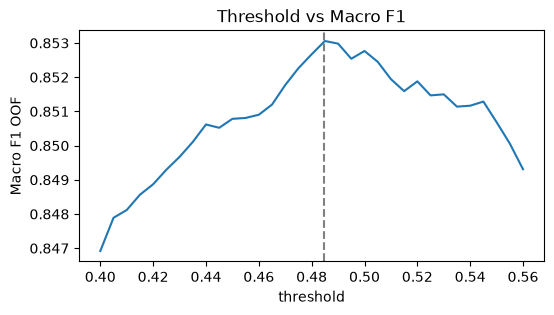

In [61]:
thresholds = np.round(np.arange(0.40, 0.56, 0.005), 4)
plt.figure(figsize=(6, 3))
plt.plot(thresholds, [macro_f1(y_clean, oof_twin >= t) for t in thresholds])
plt.axvline(CFG.THRESHOLD, linestyle='--', color='gray')
plt.xlabel('threshold'); plt.ylabel('Macro F1 OOF'); plt.title('Threshold vs Macro F1')
plt.show()

#### Insights

- Tuning di notebook eksperimen meliputi seleksi fitur, bobot fitur, k, p Minkowski, bobot jarak, scaler, clipping, cara imputasi, toleransi kembar (lead, tanggal, harga), alpha, dan threshold.
- Setiap perubahan hanya diterima kalau OOF naik di beberapa seed fold sekaligus.

### Cost-Complexity Pruning pada DTL (algoritma optimasi di luar materi)

Materi kelas membahas reduced-error pruning dan rule post-pruning. Cost-complexity pruning (weakest-link pruning) dari buku CART [1] tidak dibahas, jadi diimplementasikan sebagai algoritma optimasi tambahan untuk DTL (parameter `ccp_alpha` dan method `cost_complexity_prune` di `DecisionTree`).

**Ide.** Pohon yang dibiarkan tumbuh besar akan menghafal noise. Cost-complexity pruning memberi "denda" untuk setiap leaf:

$$R_\alpha(T) = R(T) + \alpha \cdot |\tilde{T}|$$

dengan $R(T)$ = jumlah impurity leaf yang dibobot proporsi sampel, $|\tilde{T}|$ = jumlah leaf, dan $\alpha$ = `ccp_alpha`.

**Cara kerja di kode.** Pohon ditelusuri dari bawah. Sebuah node dijadikan leaf kalau $R(\text{node}) + \alpha \le R(\text{subtree}) + \alpha \cdot |\text{leaf subtree}|$, artinya penurunan impurity dari subtree itu tidak sebanding dengan tambahan leaf-nya.

**Kenapa mengoptimasi model.** Berbeda dengan pre-pruning yang memutuskan berhenti secara lokal saat pohon tumbuh, cost-complexity pruning menilai subtree secara utuh setelah pohon jadi. Cabang yang tidak berguna dipangkas, sehingga variansi model turun. Nilai $\alpha$ dipilih dengan cross validation.

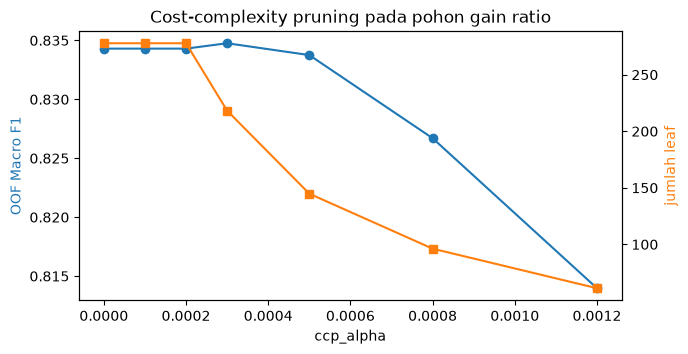

,ccp_alpha,jumlah leaf,OOF Macro F1
0,0.0000,277.8,0.8343
1,0.0001,277.8,0.8343
2,0.0002,277.8,0.8343
3,0.0003,218.2,0.8348
4,0.0005,144.8,0.8338
5,0.0008,96.2,0.8267
6,0.0012,61.2,0.8140


In [62]:
# pohon gain ratio dibangun sekali per fold, lalu dipangkas dengan alpha yang berbeda
alphas = [0.0, 1e-4, 2e-4, 3e-4, 5e-4, 8e-4, 1.2e-3]
oof_by_alpha = {a: np.zeros(len(y_clean)) for a in alphas}
leaves_by_alpha = {a: [] for a in alphas}
for eval_index, X_fit, X_eval, y_fit in dt_fold_data:
    full_tree = DecisionTree(**CFG.DT_PARAMS).fit(X_fit, y_fit)
    for a in alphas:
        tree = copy.deepcopy(full_tree).cost_complexity_prune(a) if a > 0 else full_tree
        oof_by_alpha[a][eval_index] = tree.predict_proba(X_eval)
        leaves_by_alpha[a].append(tree.get_n_leaves())

ccp_path = pd.DataFrame({'ccp_alpha': alphas,
                         'jumlah leaf': [np.mean(leaves_by_alpha[a]) for a in alphas],
                         'OOF Macro F1': [macro_f1(y_clean, oof_by_alpha[a] >= best_threshold(y_clean, oof_by_alpha[a])) for a in alphas]})

figure, axis = plt.subplots(figsize=(7, 3.5))
axis.plot(ccp_path['ccp_alpha'], ccp_path['OOF Macro F1'], marker='o', color='tab:blue')
axis.set_xlabel('ccp_alpha'); axis.set_ylabel('OOF Macro F1', color='tab:blue')
other = axis.twinx()
other.plot(ccp_path['ccp_alpha'], ccp_path['jumlah leaf'], marker='s', color='tab:orange')
other.set_ylabel('jumlah leaf', color='tab:orange')
plt.title('Cost-complexity pruning pada pohon gain ratio')
plt.show()
ccp_path.round(4)

#### Insights

> Cost-complexity pruning bisa memangkas pohon tanpa menurunkan skor.

- ccp_alpha sampai 2e-4 tidak memangkas apa pun, karena `min_impurity_decrease` 2e-4 sudah mencegah split dengan gain sekecil itu.
- ccp_alpha 3e-4 memangkas pohon dari 278 menjadi 218 leaf dan sedikit menaikkan OOF (0.8343 menjadi 0.8348). ccp_alpha 5e-4 memangkas hampir setengahnya (145 leaf) dengan OOF hampir sama (0.8338).
- Alpha 8e-4 ke atas memotong cabang yang berguna sehingga skor turun ke 0.814 sampai 0.827 (underfit).
- Di eksperimen sebelumnya, pohon gain ratio dengan ccp_alpha 3e-4 mendapat public 0.84604, sedikit di bawah tanpa ccp (0.84679). Karena itu model final tetap tanpa ccp, tetapi ccp terbukti bisa menghasilkan pohon yang jauh lebih sederhana dengan skor setara.

---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

In [63]:
sk_knn = KNeighborsClassifier(n_neighbors=CFG.K, p=CFG.P, metric='minkowski', algorithm='brute',
                              weights=lambda d: 1 / (d ** 2 + 1e-6)).fit(X_train, y_train)
sk_proba = sk_knn.predict_proba(X_val)[:, 1]

pd.DataFrame({'Macro F1 holdout': [macro_f1(y_val, val_knn >= best_threshold(y_val, val_knn)),
                                   macro_f1(y_val, sk_proba >= best_threshold(y_val, sk_proba))],
              'selisih proba maks': [0.0, float(np.abs(sk_proba - val_knn).max())]},
             index=['KNN scratch', 'KNN sklearn']).round(6)

,Macro F1 holdout,selisih proba maks
KNN scratch,0.853927,0.0
KNN sklearn,0.853927,0.0


In [64]:
# DTL: from scratch vs scikit-learn. sklearn tidak bisa membaca NaN dan teks, jadi kategori di-onehot dan missing diisi median.
# sklearn juga tidak punya gain ratio, jadi dipakai entropy dengan parameter lain yang sama.
def to_numeric(fit, *others):
    frames = [pd.get_dummies(f, columns=cat_col, dtype=float) for f in (fit,) + others]
    frames = [f.reindex(columns=frames[0].columns, fill_value=0.0) for f in frames]
    median = frames[0].median()
    return [f.fillna(median) for f in frames]

X_train_num, X_val_num = to_numeric(X_train_dt, X_val_dt)
dt_models = {
    'DTL from scratch (gain ratio)': dtl,
    'sklearn parameter sama (entropy)': DecisionTreeClassifier(criterion='entropy', max_depth=30, min_samples_leaf=5,
                                                               min_impurity_decrease=2e-4, random_state=CFG.SEED),
    'sklearn ID3 (entropy)': DecisionTreeClassifier(criterion='entropy', random_state=CFG.SEED),
    'sklearn C4.5 (entropy + ccp_alpha)': DecisionTreeClassifier(criterion='entropy', ccp_alpha=3e-4, random_state=CFG.SEED),
    'sklearn CART (gini)': DecisionTreeClassifier(criterion='gini', random_state=CFG.SEED),
}
rows = {}
for name, model in dt_models.items():
    proba = model.predict_proba(X_val_dt) if name.startswith('DTL') else model.fit(X_train_num, y_train).predict_proba(X_val_num)[:, 1]
    rows[name] = {'jumlah leaf': model.get_n_leaves(), 'Macro F1 holdout': macro_f1(y_val, proba >= DT_THRESHOLD)}
pd.DataFrame(rows).T.round(4)

,jumlah leaf,Macro F1 holdout
DTL from scratch (gain ratio),273.0,0.8372
sklearn parameter sama (entropy),480.0,0.8297
sklearn ID3 (entropy),2513.0,0.8120
sklearn C4.5 (entropy + ccp_alpha),343.0,0.8366
sklearn CART (gini),2661.0,0.8063


#### Insights

- sklearn tidak bisa membaca NaN dan teks, jadi untuk sklearn kategori di-onehot dan missing diisi median. Hasilnya mirip tetapi tidak identik dengan from scratch.
- Dengan parameter sama (sklearn memakai entropy karena tidak ada gain ratio), sklearn 480 leaf dengan holdout 0.8297, sedangkan from scratch gain ratio 273 leaf dengan holdout 0.8372. Gain ratio menghasilkan pohon lebih kecil dan lebih akurat.
- Varian spesifikasi: ID3 (entropy, tanpa batas) 0.8120 dengan 2.513 leaf, C4.5 (entropy + ccp_alpha) 0.8366 dengan 343 leaf, CART (gini, tanpa batas) 0.8063 dengan 2.661 leaf. Pohon tanpa pruning selalu paling rendah karena overfit.

---

# Saving and Loading Models <a name="9"></a>

---

<!-- artifacts: <model>_v3.pkl -->

This section stores the trained models and restores them for prediction.

In [65]:
def save_model(model, path):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    with open(path, 'wb') as f:
        pickle.dump(model, f)

def load_model(path):
    with open(path, 'rb') as f:
        return pickle.load(f)

In [66]:
final_model = KNNTwin(CFG.K, CFG.P, CFG.THRESHOLD).fit(train_clean)
save_model(final_model, CFG.MODEL_PATH)
loaded_model = load_model(CFG.MODEL_PATH)
print('model disimpan dan dimuat ulang dari', CFG.MODEL_PATH)

model disimpan dan dimuat ulang dari output/models/knn_twin_final.pkl


In [67]:
X_full_dt, X_test_dt = prepare_tree(train_clean, test_df)
final_dtl = DecisionTree(**CFG.DT_PARAMS).fit(X_full_dt, y_clean)
save_model({'model': final_dtl, 'threshold': DT_THRESHOLD}, CFG.DT_MODEL_PATH)
dtl_bundle = load_model(CFG.DT_MODEL_PATH)
print('DTL disimpan dan dimuat ulang dari', CFG.DT_MODEL_PATH, ' jumlah leaf', dtl_bundle['model'].get_n_leaves())

DTL disimpan dan dimuat ulang dari output/models/dtl_gain_ratio.pkl  jumlah leaf 253


---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [68]:
submission = pd.DataFrame({CFG.ID_COLUMN: test_df[CFG.ID_COLUMN], CFG.TARGET: loaded_model.predict(test_df)})
Path(CFG.SUB_PATH).parent.mkdir(parents=True, exist_ok=True)
submission.to_csv(CFG.SUB_PATH, index=False)

print('rasio batal prediksi', submission[CFG.TARGET].mean().round(4))
print('md5 submission:', hashlib.md5(open(CFG.SUB_PATH, 'rb').read()).hexdigest())
submission.head()

rasio batal prediksi 0.3086
md5 submission: 39505c42f93d193ce99a023cabd3e9d9


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


Submission DTL juga dibuat untuk membuktikan model DTL reproducible: md5-nya harus sama dengan submission DTL terbaik (public 0.84679).

In [69]:
dtl_submission = pd.DataFrame({CFG.ID_COLUMN: test_df[CFG.ID_COLUMN],
                               CFG.TARGET: dtl_bundle['model'].predict(X_test_dt, threshold=dtl_bundle['threshold'])})
dtl_submission.to_csv(CFG.DT_SUB_PATH, index=False)
print('md5 submission DTL:', hashlib.md5(open(CFG.DT_SUB_PATH, 'rb').read()).hexdigest())

md5 submission DTL: 71abf10d033c2f0c8f5912b94ab2ba51


---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.

## Confusion Matrix

In [70]:
oof_pred = (oof_twin >= CFG.THRESHOLD).astype(int)
print('confusion matrix OOF [[TN, FP], [FN, TP]]')
print(confusion_matrix(y_clean, oof_pred))
print('F1 kelas 0, kelas 1:', f1_score(y_clean, oof_pred, average=None).round(4))

confusion matrix OOF [[TN, FP], [FN, TP]]
[[16728  1637]
 [ 1877  7067]]
F1 kelas 0, kelas 1: [0.9049 0.8009]


## Kesalahan per Kelompok

In [71]:
def error_by(values, name):
    frame = pd.DataFrame({name: values, 'error': oof_pred != y_clean})
    return frame.groupby(name, observed=True, dropna=False)['error'].agg(['mean', 'size']).round(3)

In [72]:
_, oof_count = twin_vote(train_clean, train_clean, y_clean, CFG.TWIN_LEAD, CFG.TWIN_DAY, CFG.TWIN_PRICE)
error_by(np.where(oof_count - 1 >= CFG.TWIN_MIN, 'punya kembar', 'tanpa kembar'), 'kembar')

,mean,size
kembar,,
punya kembar,0.055,8221
tanpa kembar,0.161,19088


In [73]:
error_by(pd.qcut(train_clean['days_before_arrival'], 5, duplicates='drop'), 'days_before_arrival')

,mean,size
days_before_arrival,,
"(-0.001, 11.0]",0.088,5286
"(11.0, 39.0]",0.132,5332
"(39.0, 80.0]",0.151,5186
"(80.0, 151.0]",0.183,5180
"(151.0, 448.0]",0.080,5205
NaN,0.177,1120


In [74]:
error_by(train_clean['special_requests'], 'special_requests')

,mean,size
special_requests,,
0.0,0.136,12678
1.0,0.140,8323
2.0,0.075,3246
3.0,0.002,496
4.0,0.000,60
5.0,0.000,7
NaN,0.152,2499


#### Insights

- Baris yang punya kembar diprediksi jauh lebih akurat daripada baris tanpa kembar.
- Sisa kesalahan terkumpul di baris tanpa kembar dengan lead time menengah, di mana tetangga terdekatnya campur antara batal dan tidak batal.

## Gambar Percabangan DTL

`plot_tree` menggambar `top_n` level teratas pohon DTL final. Leaf merah berarti mayoritas batal, hijau mayoritas tidak batal.

In [75]:
# Gambar percabangan pohon sampai kedalaman top_n.
def split_text(model, node):
    if node.is_cat:
        return model.describe_split(node)
    name, value = model.feature_names_[node.feature], node.threshold
    return f'{name} <= {value:,.0f}' if abs(value) >= 1000 else f'{name} <= {value:.4g}'

def plot_tree(model, top_n=3, save_path=None):
    figure, axis = plt.subplots(figsize=(2.8 * 2 ** top_n, 1.7 * (top_n + 1)))

    def draw(node, depth, x_min, x_max, parent=None):
        x, y = (x_min + x_max) / 2, -depth
        stop = node.is_leaf or depth == top_n
        text = (f'p(batal) = {node.value:.2f}\nn = {node.n_samples}' + ('' if node.is_leaf else '\n(lanjut)') if stop
                else f'{split_text(model, node)}\nn = {node.n_samples}')
        axis.text(x, y, text, ha='center', va='center', fontsize=8,
                  bbox=dict(boxstyle='round', fc='mistyrose' if stop and node.value >= 0.5 else 'honeydew' if stop else 'aliceblue'))
        if parent is not None:
            axis.plot([parent[0], x], [parent[1] - 0.22, y + 0.22], color='gray', lw=0.8)
        if not stop:
            mid = (x_min + x_max) / 2
            draw(node.left, depth + 1, x_min, mid, (x, y))
            draw(node.right, depth + 1, mid, x_max, (x, y))

    draw(model.root_, 0, 0, 1)
    axis.set_xlim(0, 1)
    axis.set_ylim(-top_n - 0.6, 0.6)
    axis.axis('off')
    axis.set_title(f'{top_n} level teratas Decision Tree (cabang kiri = kondisi benar)')
    if save_path is not None:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        figure.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

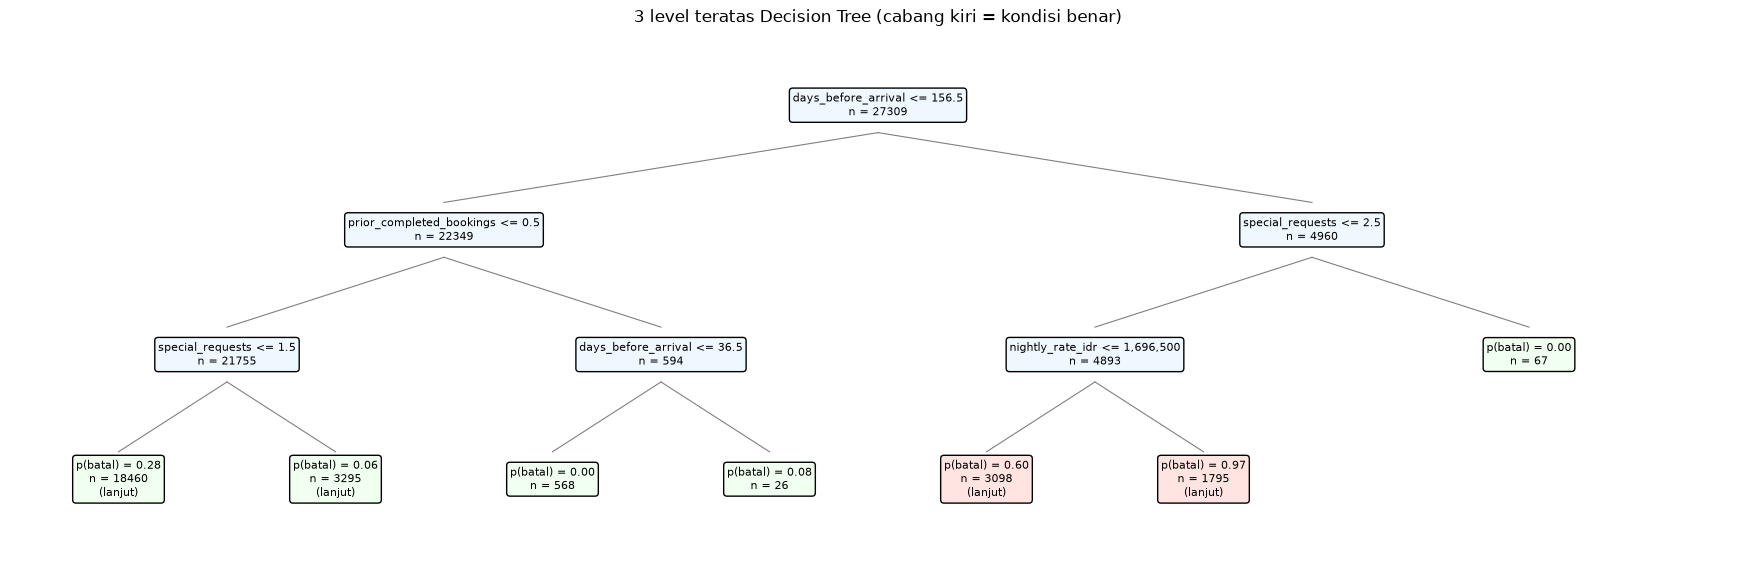

In [76]:
plot_tree(final_dtl, top_n=3, save_path='output/figures/dtl_tree_top3.png')

#### Insights

- Split pertama adalah lead time di 156,5 hari, sesuai EDA bahwa lead time adalah fitur terkuat.
- Booking jauh hari dengan special_requests maksimal 2 dan harga per malam di atas sekitar Rp1,7 juta hampir pasti batal (97%). Kalau special_requests 3 atau lebih, tidak ada yang batal.
- Untuk booking dekat hari, pohon memisahkan tamu baru dan tamu yang pernah menginap (`prior_completed_bookings`). Tamu lama dengan lead time di bawah 37 hari tidak ada yang batal (568 baris), dan tamu baru dengan 2 atau lebih special_requests hanya 6% batal.

---

# Cost-sensitive Classification <a name="12"></a>

---

False Positive (diprediksi batal, ternyata datang) lebih mahal karena penginapan bisa overbooked. Diasumsikan biaya FP = 2 dan FN = 1, jadi total biaya = 2 x FP + FN.

Dengan probabilitas yang terkalibrasi, keputusan dengan biaya harapan minimum adalah memprediksi batal kalau $p \cdot C_{FN} > (1 - p) \cdot C_{FP}$, yaitu $p > \frac{C_{FP}}{C_{FP} + C_{FN}} = \frac{2}{3}$ [2]. Threshold juga dicari langsung dari prediksi OOF model final (KNN + kembar).

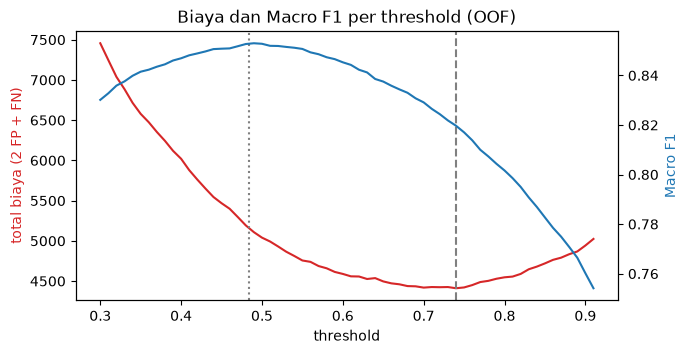

,threshold,FP,FN,total biaya,Macro F1,rasio prediksi batal
threshold Macro F1,0.4845,1637.0,1877.0,5151.0,0.8529,0.3187
threshold teori 2/3,0.6667,764.0,2931.0,4459.0,0.8350,0.2482
threshold biaya minimum,0.7400,494.0,3423.0,4411.0,0.8197,0.2203


In [77]:
def total_cost(y_true, pred):
    fp = int(((pred == 1) & (y_true == 0)).sum())
    fn = int(((pred == 0) & (y_true == 1)).sum())
    return CFG.COST_FP * fp + CFG.COST_FN * fn, fp, fn

thresholds = np.round(np.arange(0.30, 0.91, 0.01), 2)
costs = np.array([total_cost(y_clean, (oof_twin >= t).astype(int))[0] for t in thresholds])
f1s = np.array([macro_f1(y_clean, oof_twin >= t) for t in thresholds])
cost_threshold = float(thresholds[np.argmin(costs)])
theory_threshold = CFG.COST_FP / (CFG.COST_FP + CFG.COST_FN)

rows = {}
for name, t in [('threshold Macro F1', CFG.THRESHOLD), ('threshold teori 2/3', theory_threshold), ('threshold biaya minimum', cost_threshold)]:
    pred = (oof_twin >= t).astype(int)
    cost, fp, fn = total_cost(y_clean, pred)
    rows[name] = {'threshold': round(t, 4), 'FP': fp, 'FN': fn, 'total biaya': cost,
                  'Macro F1': round(macro_f1(y_clean, pred), 4), 'rasio prediksi batal': round(pred.mean(), 4)}
cost_table = pd.DataFrame(rows).T

figure, axis = plt.subplots(figsize=(7, 3.5))
axis.plot(thresholds, costs, color='tab:red'); axis.set_ylabel('total biaya (2 FP + FN)', color='tab:red')
other = axis.twinx(); other.plot(thresholds, f1s, color='tab:blue'); other.set_ylabel('Macro F1', color='tab:blue')
for t, style in [(CFG.THRESHOLD, ':'), (cost_threshold, '--')]:
    axis.axvline(t, linestyle=style, color='gray')
axis.set_xlabel('threshold'); plt.title('Biaya dan Macro F1 per threshold (OOF)')
plt.show()
cost_table

#### Insights

> Kalau FP 2 kali lebih mahal, threshold dinaikkan dari 0.4845 ke sekitar 0.67 sampai 0.74.

- Dengan threshold Macro F1 (0.4845), total biaya 5.151 (1.637 FP dan 1.877 FN).
- Threshold teori 2/3 menurunkan biaya menjadi 4.459 (-13%), dan threshold biaya minimum dari OOF (0.74) menurunkan biaya menjadi 4.411 (-14%). Threshold empiris dekat dengan teori, jadi probabilitas model cukup terkalibrasi.
- Harganya: FP turun dari 1.637 menjadi 494, tetapi FN naik dari 1.877 menjadi 3.423, dan Macro F1 turun dari 0.8529 menjadi 0.8197. Model jadi lebih hati-hati dan hanya memprediksi batal kalau yakin (rasio prediksi batal 32% menjadi 22%).
- Penanganannya berubah dari memaksimalkan Macro F1 menjadi meminimalkan biaya: model dan preprocessing tetap, yang diubah hanya threshold keputusan. Untuk kompetisi tetap dipakai threshold Macro F1 karena metrik Kaggle adalah Macro F1.

---

# Referensi <a name="13"></a>

---

[1] L. Breiman, J. H. Friedman, R. A. Olshen, and C. J. Stone, *Classification and Regression Trees*. Belmont, CA: Wadsworth, 1984. (cost-complexity pruning, bab 3)

[2] C. Elkan, "The Foundations of Cost-Sensitive Learning," in *Proc. 17th International Joint Conference on Artificial Intelligence (IJCAI)*, 2001, pp. 973 to 978.

[3] J. R. Quinlan, *C4.5: Programs for Machine Learning*. San Mateo, CA: Morgan Kaufmann, 1993. (gain ratio)